# Scientific publication extraction: structure as an explicit prior

This worked example asks: **what becomes possible when we represent a scientific publication using an explicit structural model?**

We compare three representations of the same PDF:

1. **Less informed:** a sequence of pages containing text.
2. **Schema informed:** title/front matter, sections, figures, tables, references, page ranges, evidence, and explicitly unidentified content.
3. **Schema informed with targeted visual recovery:** the text pass runs first; only its unresolved regions or conflicting classifications are sent to a local vision model.

The default example is `Simon_2025_TMAP8_manuscript.pdf`; the configuration cell identifies the input for this saved execution. The algorithms are reusable; the paper name is an input, not an extraction rule. The current mistakes are deliberately retained and examined. More explicit structure makes queries, validation and targeted recovery possible; it does **not** establish better accuracy by itself.

**How to read this notebook:** narrative cells explain the design; implementation cells show the working functions; execution cells construct and inspect the representations. All saved outputs come from actual runs. Cached model evidence is reused on rerun.

## 1. Configuration and reproducibility

Run with the project's `.local/scientific-vision-env` Python environment. PDF processing and saved-result inspection need no network. Fresh visual recovery uses the locally downloaded **Qwen/Qwen3-VL-4B-Instruct** checkpoint on the GPU. Its exact revision is recorded below.

Keep this notebook in `Teaching/DSE203/publication_structure/notebooks`. Source PDFs, companion extraction modules and the existing model environment remain in FEDER; generated outputs live under the teaching folder. Change `PDF_NAME` to use another paper. The three supplied inputs are `Murari_2024_Control_oriented_disruption_prediction.pdf`, `Spangher_2025_DisruptionBench.pdf`, and `Simon_2025_TMAP8_manuscript.pdf`. Each input has its own output directory and response cache. `FORCE_TEXT_PASS=True` rebuilds the text result and region plan; otherwise an unchanged source and validated cache are reused. The model runs only for requests absent from the matching cache.

Model documentation: [Qwen3-VL-4B-Instruct](https://huggingface.co/Qwen/Qwen3-VL-4B-Instruct). Runtime dependencies are in `scripts/scientific_vision_requirements.txt`.

In [1]:
from pathlib import Path
import sys, json, re, hashlib, copy, time, unicodedata, argparse
import base64, io, urllib.request, urllib.error, html
from collections import Counter, defaultdict
from dataclasses import dataclass, field
import pdfplumber, jsonschema
from IPython.display import display, HTML, JSON, Image, Math, Markdown, FileLink

# Configure the canonical project location and import the companion extraction modules.
ROOT = Path(r"C:\Users\Amarnath Gupta\OneDrive - UC San Diego\Documents\Codex\FEDER")
sys.path.insert(0, str(ROOT / "scripts"))
TEACHING_ROOT = ROOT.parent / "Teaching" / "DSE203"
PUBLICATION_ROOT = TEACHING_ROOT / "publication_structure"

# Choose the input paper; all output paths are derived from this filename.
PDF_NAME = 'Simon_2025_TMAP8_manuscript.pdf'
PDF = ROOT / "docs" / "Publications" / PDF_NAME
SCHEMA_PATH = PUBLICATION_ROOT / "notebooks" / "scientific_publication.schema.json"
OUTPUT = (
    PUBLICATION_ROOT
    / "outputs"
    / "publication_structures"
    / "text_then_vision"
    / PDF.stem
)
FORCE_TEXT_PASS = False
OUTPUT.mkdir(parents=True, exist_ok=True)
assert PDF.is_file(), PDF
SOURCE_SHA256 = hashlib.sha256(PDF.read_bytes()).hexdigest()
print("PDF:", PDF.name, "| SHA-256:", SOURCE_SHA256)
print("Python:", sys.version.split()[0], "| pdfplumber:", pdfplumber.__version__)


PDF: Simon_2025_TMAP8_manuscript.pdf | SHA-256: 1e9ba94fbf550bafe1031981b821b4ab690b4114834f65677f2575103d9b0f71
Python: 3.12.14 | pdfplumber: 0.11.10


In [2]:
# Render a compact comparison table while escaping source text before inserting it into HTML.
def show_table(rows, columns):
    """Small dependency-free table; escape source text before rendering it."""
    header = "".join(f"<th>{html.escape(c)}</th>" for c in columns)
    body = "".join(
        "<tr>"
        + "".join(f"<td>{html.escape(str(row.get(c, '')))}</td>" for c in columns)
        + "</tr>"
        for row in rows
    )
    display(
        HTML(
            "<style>table.pub{border-collapse:collapse;font-size:14px}table.pub th,table.pub td{border:1px solid #cbd5e1;padding:7px;text-align:left;vertical-align:top}table.pub th{background:#e2e8f0}</style><table class='pub'><thead><tr>"
            + header
            + "</tr></thead><tbody>"
            + body
            + "</tbody></table>"
        )
    )


### Inspecting and downloading the complete JSON

Each stage below displays its **complete** JSON in an expandable viewer, not a truncated sample. Expand the object to inspect nested elements. A download link provides the same full JSON as a standalone file. Stage 3 contains unverified visual proposals; stage 4 is the final schema-validated document with unresolved content retained.

In [3]:
# Save and display the same complete stage result, with a direct Jupyter download link.
def publish_json(filename, value, label):
    """Save and display the same complete object, with a Jupyter download link."""
    directory = OUTPUT / "json_stages"
    directory.mkdir(exist_ok=True)
    path = directory / filename
    path.write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding="utf-8")
    assert json.loads(path.read_text(encoding="utf-8")) == value
    href = "/files/" + path.relative_to(TEACHING_ROOT).as_posix()
    display(
        HTML(
            f'<h3>{html.escape(label)}</h3><p><a href="{html.escape(href, quote=True)}" download="{html.escape(filename, quote=True)}" target="_blank">Download complete {html.escape(filename)}</a></p>'
        )
    )
    display(JSON(value, expanded=False))
    print("Saved:", path)
    return path


## 2. A less informed representation

The baseline knows only that the source is a PDF with ordered pages. It does not assign semantic roles or distinguish a heading, equation, caption or reference entry. Its text can still be searched; the missing information is an explicit representation of relationships and roles.

In [4]:
# Construct the less-informed baseline directly from each PDF page.
with pdfplumber.open(PDF) as pdf:
    flat_document = {
        "source": {"pdf": str(PDF), "sha256": SOURCE_SHA256, "pages": len(pdf.pages)},
        "pages": [
            {"page": i + 1, "text": page.extract_text() or ""}
            for i, page in enumerate(pdf.pages)
        ],
    }
(OUTPUT / "flat_text_baseline.json").write_text(
    json.dumps(flat_document, indent=2, ensure_ascii=False), encoding="utf-8"
)
print("Pages:", len(flat_document["pages"]))
print("Text characters:", sum(len(p["text"]) for p in flat_document["pages"]))
display(
    JSON(
        {
            "page": flat_document["pages"][0]["page"],
            "text_preview": flat_document["pages"][0]["text"][:1100],
        }
    )
)


Pages: 26
Text characters: 123918


<IPython.core.display.JSON object>

In [5]:
flat_json_path = publish_json(
    "01_flat_page_text.json", flat_document, "Stage 1 — Complete page-text baseline"
)


<IPython.core.display.JSON object>

Saved: C:\Users\Amarnath Gupta\OneDrive - UC San Diego\Documents\Codex\Teaching\DSE203\publication_structure\outputs\publication_structures\text_then_vision\Simon_2025_TMAP8_manuscript\json_stages\01_flat_page_text.json


## 3. The scientific-publication model

The recursive schema defines **possible** publication structure. Optional content stays optional. Every structural element has inclusive, one-based physical PDF `page_start` and `page_end` values—even a parsed citation component.

An article contains front matter, body and back matter. Sections can contain subsections; appendices can have their own section hierarchy. References can contain a citation subtree. Unknown structure is represented by `type="custom"` and `attributes.custom_type="unidentified"`.

This schema constrains interpretation; it does not tell us that a particular line is a heading. That decision needs typography, reading order, source text and sometimes an image. Bounding boxes remain internal processing metadata and are omitted from publication JSON.

In [6]:
# Load and validate the structural contract before using it to interpret content.
SCHEMA = json.loads(SCHEMA_PATH.read_text(encoding="utf-8"))
jsonschema.Draft202012Validator.check_schema(SCHEMA)
print("Schema:", SCHEMA["$id"])
show_table(
    [
        {"Element": "article", "Possible children": "front_matter, body, back_matter"},
        {
            "Element": "section / appendix",
            "Possible children": "sections, subsections, paragraphs, equations, figures, tables",
        },
        {
            "Element": "references",
            "Possible children": "reference → citation → authors, title, year, venue, identifiers…",
        },
        {"Element": "acknowledgements", "Possible children": "optional paragraph"},
        {
            "Element": "custom: unidentified",
            "Possible children": "preserved source content awaiting interpretation",
        },
    ],
    ["Element", "Possible children"],
)

# Demonstrate which structural requirements the flat page-text representation lacks.
flat_errors = list(jsonschema.Draft202012Validator(SCHEMA).iter_errors(flat_document))
print("The page-text baseline does not implement this structural contract:")
for error in flat_errors[:4]:
    print(" •", error.message)


Schema: urn:scientific-publication:structure:1.1


Element,Possible children
article,"front_matter, body, back_matter"
section / appendix,"sections, subsections, paragraphs, equations, figures, tables"
references,"reference → citation → authors, title, year, venue, identifiers…"
acknowledgements,optional paragraph
custom: unidentified,preserved source content awaiting interpretation


The page-text baseline does not implement this structural contract:
 • Additional properties are not allowed ('pages' was unexpected)
 • 'schema_version' is a required property
 • 'extraction' is a required property
 • 'document' is a required property


### 4.1 Node construction and structural validation

The first checks are mechanical: required fields, unique IDs, valid page ranges and parent/child containment. Passing these checks is not proof of semantic correctness.

The following is executable implementation code, copied from the companion script at notebook creation, formatted and annotated by logical block. Comments and spacing are checked to preserve the executable syntax.

In [7]:
# Create one schema element with an inclusive physical-page interval and child list.
def node(identifier, role, start, end=None, **fields):
    return dict(
        id=identifier,
        type=role,
        page_start=start,
        page_end=start if end is None else end,
        children=[],
        **fields
    )


In [8]:
# Traverse the hierarchy in preorder so every element can be inspected uniformly.
def walk(n):
    yield n
    for c in n["children"]:
        yield from walk(c)


In [9]:
# Build an ID lookup for resolving parents, evidence links and replacement targets.
def index(tree):
    return {n["id"]: n for n in walk(tree["document"])}


In [10]:
# Propagate child page intervals upward so each container encloses its contents.
def expand_ranges(n):
    for c in n["children"]:
        expand_ranges(c)
    if n["children"]:
        n["page_start"] = min(
            [n["page_start"]] + [c["page_start"] for c in n["children"]]
        )
        n["page_end"] = max([n["page_end"]] + [c["page_end"] for c in n["children"]])


In [11]:
# Check the schema and mechanical invariants; this does not certify interpretation accuracy.
def validate_structure(tree, schema):
    jsonschema.Draft202012Validator(schema).validate(tree)

    # Track node IDs while checking page bounds, containment and geometry exclusion.
    seen = set()

    def visit(n, parent=None):
        assert n["id"] not in seen, "Duplicate node ID: " + n["id"]
        seen.add(n["id"])
        assert (
            1 <= n["page_start"] <= n["page_end"] <= tree["source"]["pages"]
        ), "Invalid page interval"
        assert (
            "source" not in n and "bbox" not in n
        ), "Geometry is forbidden in structural output"
        if parent:
            assert (
                parent["page_start"]
                <= n["page_start"]
                <= n["page_end"]
                <= parent["page_end"]
            ), "Child outside parent"
        for c in n["children"]:
            visit(c, n)

    visit(tree["document"])

    # Check affiliation links after collecting the complete set of nodes.
    ids = index(tree)
    for n in ids.values():
        for aid in n.get("affiliation_ids", []):
            assert (
                aid in ids and ids[aid]["type"] == "affiliation"
            ), "Broken affiliation link"
    return {
        "schema_valid": True,
        "page_ranges_valid": True,
        "unique_ids": True,
        "nodes": len(seen),
    }


### 4.2 Lines, typography and reading order

The local pass groups PDF characters into lines, uses whitespace and horizontal rules to infer reading order, and records font information. Two-column and mixed layouts remain a source of error. The optional earlier full-page provider is imported only for API compatibility; this workflow always runs its text pass with `visual=False`.

The following is executable implementation code, copied from the companion script at notebook creation, formatted and annotated by logical block. Comments and spacing are checked to preserve the executable syntax.

In [12]:
# Group PDF characters into text lines while retaining their private geometric evidence.
def char_line_records(chars):
    if not chars:
        return []
    from pdfplumber.utils import chars_to_textmap

    return chars_to_textmap(
        chars, layout=False, x_tolerance_ratio=0.15, y_tolerance=3
    ).extract_text_lines(strip=True, return_chars=True)


In [13]:
# Return just the text when the caller does not need character-level evidence.
def char_lines(chars):
    return [line["text"] for line in char_line_records(chars)]


In [14]:
# Infer reading order within page bands, allowing both column text and spanning content.
def ordered_page_lines(
    page, pno, pdf_hash, enable_visual=False, body_font_size=None, ctx=None
):

    # Initialize ordered lines and preserve compatibility with optional earlier adapters.
    ordered = []
    if ctx and ctx.vision_results:
        from hf_equation_integration import load_page_proposals

        ctx.equation_proposals.extend(
            load_page_proposals(ctx.vision_results, pno, pdf_hash, page)
        )
    summary = {
        "page": pno,
        "method": "local_geometry_fallback",
        "review_required": True,
    }
    if enable_visual and not ctx.visual_blocked:
        try:
            plan, evidence = visual_layout(page, pno, pdf_hash, ctx)
            ctx.layout_evidence.append(evidence)
            summary.update(
                method="visual_model_proposal",
                layout=plan["layout"],
                review_required=not plan["complete"] or bool(plan["uncertainties"]),
            )
            ctx.add_visual_assets(page, pno, plan)
            remaining = list(page.chars)
            for order, r in enumerate(plan["regions"], 1):
                chars = [
                    c
                    for c in remaining
                    if r["x0"]
                    <= 1000 * (c["x0"] + c["x1"]) / (2 * page.width)
                    < r["x1"]
                    and r["y0"]
                    <= 1000 * (c["top"] + c["bottom"]) / (2 * page.height)
                    < r["y1"]
                ]
                assigned = {id(c) for c in chars}
                remaining = [c for c in remaining if id(c) not in assigned]
                for ln in char_line_records(chars):
                    ordered.append(
                        dict(
                            ln,
                            flow=r["column"],
                            region_kind=r["kind"],
                            reading_order=order,
                            visual_heading_level=r["heading_level"],
                        )
                    )
            if remaining:
                summary.update(
                    review_required=True, unassigned_characters=len(remaining)
                )
                for ln in char_line_records(remaining):
                    ordered.append(
                        dict(
                            ln,
                            flow="unidentified",
                            region_kind="unidentified",
                            reading_order=len(plan["regions"]) + 1,
                        )
                    )
            return ordered, summary
        except Exception as exc:
            summary["visual_failure"] = (
                str(exc)[:200]
                if isinstance(exc, (RuntimeError, AssertionError))
                else type(exc).__name__
            )
            ctx.visual_blocked = True
    # Analyze separate vertical bands. Long horizontal rules often delimit a header,
    # spanning table, or figure; one page-wide gutter can otherwise be dominated by table columns.

    # Start local layout analysis from the PDF text and horizontal separators.
    raw_lines = page.extract_text_lines(layout=False, strip=True)
    # PDF table rules can be stored as many adjoining short segments.
    rows = {}
    for edge in page.edges:
        if abs(edge.get("bottom", 0) - edge.get("top", 0)) <= 1:
            rows.setdefault(round(float(edge["top"]), 1), []).append(
                (edge["x0"], edge["x1"])
            )
    rule_y = []
    for y, intervals in rows.items():
        start = end = None
        for x0, x1 in sorted(intervals):
            if start is None:
                start, end = x0, x1
            elif x0 <= end + 2.5:
                end = max(end, x1)
            else:
                if end - start >= page.width * 0.5:
                    rule_y.append(y)
                start, end = x0, x1
        if start is not None and end - start >= page.width * 0.5:
            rule_y.append(y)
    boundaries = [0.0]
    for y in sorted(rule_y):
        if y > boundaries[-1] + 2 and y < page.height - 2:
            boundaries.append(y)
    boundaries.append(float(page.height))

    # Score plausible gutters using body-sized characters rather than small table text.
    candidates = [page.width * (0.30 + i * 0.01) for i in range(41)]
    content_size = (
        body_font_size
        or Counter(round(c.get("size", 0), 1) for c in page.chars).most_common(1)[0][0]
        if page.chars
        else 10
    )

    def gap_support(line, split):
        # Use body-size text for gutter voting so small table cells cannot dominate the body layout.
        chars = [
            c
            for c in line.get("chars", [])
            if c.get("text", "").strip() and c.get("size", 0) >= content_size * 0.95
        ]
        left = [c for c in chars if c["x1"] <= split]
        right = [c for c in chars if c["x0"] >= split]
        return bool(
            left
            and right
            and not any(c["x0"] < split < c["x1"] for c in chars)
            and min(c["x0"] for c in right) - max(c["x1"] for c in left)
            >= page.width * 0.015
        )

    order = 0
    band_layouts = []

    # Process each vertical band independently; one page can mix different layouts.
    for low, high in zip(boundaries, boundaries[1:]):
        band = [
            line
            for line in raw_lines
            if low <= min(c["top"] for c in line["chars"]) < high
        ]
        if not band:
            continue
        # Bibliographies often use a smaller font than the article body.
        band_sizes = Counter(
            round(c.get("size", 0), 1)
            for line in band
            for c in line["chars"]
            if c.get("text", "").strip()
        )
        if band_sizes and sum(
            any(c.get("size", 0) >= content_size * 0.95 for c in line["chars"])
            for line in band
        ) < max(3, len(band) * 0.12):
            content_size = band_sizes.most_common(1)[0][0]
        scores = [sum(gap_support(line, s) for line in band) for s in candidates]
        best = max(
            range(len(scores)),
            key=lambda k: (scores[k], -abs(candidates[k] - page.width / 2)),
        )
        split = candidates[best]
        eligible = sum(
            any(
                c.get("text", "").strip() and c.get("size", 0) >= content_size * 0.95
                for c in line["chars"]
            )
            for line in band
        )
        two = scores[best] >= max(3, eligible * 0.12)
        if not two:
            for line in band:
                order += 1
                ordered.append(
                    dict(
                        line,
                        flow="spanning_or_single",
                        region_kind="text",
                        reading_order=order,
                    )
                )
            band_layouts.append("spanning_or_single")
            continue

        # Buffer column lines and flush them before a spanning line interrupts the columns.
        pending_left = []
        pending_right = []
        had_span = False

        def flush():
            nonlocal order
            for flow, items in [("left", pending_left), ("right", pending_right)]:
                for ln in items:
                    order += 1
                    ordered.append(
                        dict(ln, flow=flow, region_kind="text", reading_order=order)
                    )
            pending_left.clear()
            pending_right.clear()

        for line in band:
            chars = line.get("chars", [])
            left = [c for c in chars if (c["x0"] + c["x1"]) / 2 < split]
            right = [c for c in chars if (c["x0"] + c["x1"]) / 2 >= split]
            # Test the actual character gap here, not the body-font voting subset.
            nonspace = [c for c in chars if c.get("text", "").strip()]
            l = [c for c in nonspace if c["x1"] <= split]
            r = [c for c in nonspace if c["x0"] >= split]
            actual_gap = bool(
                l
                and r
                and not any(c["x0"] < split < c["x1"] for c in nonspace)
                and min(c["x0"] for c in r) - max(c["x1"] for c in l)
                >= page.width * 0.015
            )
            spanning = bool(left and right) and not actual_gap
            if spanning:
                flush()
                order += 1
                had_span = True
                ordered.append(
                    dict(line, flow="spanning", region_kind="text", reading_order=order)
                )
            else:
                pending_left.extend(char_line_records(left))
                pending_right.extend(char_line_records(right))
        flush()
        band_layouts.append("mixed" if had_span else "two_column")

    # Report the inferred layout and keep its uncertainty available to later stages.
    summary.update(
        layout=(
            "mixed"
            if (
                "mixed" in band_layouts
                or (
                    "two_column" in band_layouts
                    and "spanning_or_single" in band_layouts
                )
            )
            else "two_column" if "two_column" in band_layouts else "single_or_uncertain"
        ),
        band_count=len(band_layouts),
        band_layouts=band_layouts,
        raw_line_count=len(raw_lines),
    )
    if ctx and ctx.equation_proposals:
        for line in ordered:
            chars = line.get("chars", [])
            if not chars:
                continue
            box = (
                min(c["x0"] for c in chars),
                min(c["top"] for c in chars),
                max(c["x1"] for c in chars),
                max(c["bottom"] for c in chars),
            )
            if any(
                e["page"] == pno and overlap_fraction(box, e["box"]) >= 0.5
                for e in ctx.equation_proposals
            ):
                line["region_kind"] = "equation"
        summary["huggingface_equation_proposals"] = sum(
            e["page"] == pno for e in ctx.equation_proposals
        )
    return ordered, summary


In [15]:
# Compatibility hook used only if the older parser is explicitly called with visual=True.
# The workflow in this notebook never invokes that provider.
from document_structure_extractor import visual_layout


### 4.3 First structural pass

Headings are inferred relative to the document’s body font and style, with support for numbering, bold, italic and centered text. Exact standard labels provide additional evidence. Content not assigned a role is retained as unidentified; it is not silently discarded.

The following is executable implementation code, copied from the companion script at notebook creation, formatted and annotated by logical block. Comments and spacing are checked to preserve the executable syntax.

In [16]:
# Learn the paper typography, propose heading roles, and construct the initial document hierarchy.
def first_pass(pdf_path, ctx, enable_visual=False):
    from statistics import median

    # Fingerprint the source and learn the dominant body size and font family.
    pages = []
    pdf_hash = hashlib.sha256(pdf_path.read_bytes()).hexdigest()
    with pdfplumber.open(pdf_path) as pdf:
        total = len(pdf.pages)
        sizes = Counter(
            Counter(
                round(c.get("size", 0), 1)
                for c in page.chars
                if c.get("text", "").strip()
            ).most_common(1)[0][0]
            for page in pdf.pages
            if page.chars
        )
        body_size = sizes.most_common(1)[0][0] if sizes else 10
        families = Counter(
            c.get("fontname", "").split("+")[-1]
            for page in pdf.pages
            for c in page.chars
            if abs(c.get("size", 0) - body_size) < 0.6
        )
        body_family = families.most_common(1)[0][0] if families else ""

        # Visit physical pages in order and remove duplicate PDF glyphs before analysis.
        for pno, page in enumerate(pdf.pages, 1):
            page = page.dedupe_chars(tolerance=1)
            ordered, layout = ordered_page_lines(
                page, pno, pdf_hash, enable_visual, body_size, ctx
            )
            lines = []
            last_bottom = {}

            # Measure each line: font, emphasis, spacing, reading flow and private bounds.
            for k, line in enumerate(ordered, 1):
                lc = [c for c in line.get("chars", []) if c.get("text", "").strip()]
                font_size = round(median(c.get("size", 0) for c in lc), 1) if lc else 0
                italic_ratio = (
                    sum(
                        any(
                            tag in c.get("fontname", "").lower()
                            for tag in ("italic", "oblique")
                        )
                        for c in lc
                    )
                    / len(lc)
                    if lc
                    else 0
                )
                font_family = (
                    Counter(
                        c.get("fontname", "").split("+")[-1] for c in lc
                    ).most_common(1)[0][0]
                    if lc
                    else ""
                )
                box = (
                    (
                        min(c["x0"] for c in lc),
                        min(c["top"] for c in lc),
                        max(c["x1"] for c in lc),
                        max(c["bottom"] for c in lc),
                    )
                    if lc
                    else (0, 0, 0, 0)
                )
                bold_ratio = (
                    sum("bold" in c.get("fontname", "").lower() for c in lc) / len(lc)
                    if lc
                    else 0
                )
                top = min(c["top"] for c in lc) if lc else 0
                bottom = max(c["bottom"] for c in lc) if lc else top
                flow = line["flow"]
                gap = top - last_bottom.get(flow, top)
                last_bottom[flow] = bottom
                text = line["text"].strip()
                # A short, separate typographic unit, not inline emphasis, captions or author lists.
                short = (
                    3 <= len(text) <= 125
                    and len(text.split()) <= 16
                    and not re.search(r"[.!?;]$", text)
                )
                excluded = (
                    bool(
                        re.match(
                            r"^(?:fig(?:ure)?\.?|table|https?://|doi\b)", text, re.I
                        )
                    )
                    or "·" in text
                    or "@" in text
                )
                supported = (
                    (
                        bold_ratio >= 0.7
                        or italic_ratio >= 0.7
                        or font_size > body_size * 1.08
                        or font_family != body_family
                        or line.get("region_kind") == "heading"
                    )
                    and short
                    and not excluded
                )
                if (
                    font_size <= body_size * 1.05
                    and gap < font_size * 0.4
                    and line.get("region_kind") != "heading"
                ):
                    supported = False
                title_candidate = (
                    pno == 1
                    and top / page.height < 0.40
                    and font_size >= body_size * 1.35
                    and supported
                )

                # Retain observations and features so later decisions can be traced to source lines.
                item = {
                    "id": f"p{pno}_l{k}",
                    "page": pno,
                    "text": text,
                    "flow": flow,
                    "reading_order": line["reading_order"],
                    "region_kind": line["region_kind"],
                    "heading_typography": supported,
                    "font_size": font_size,
                    "bold_ratio": round(bold_ratio, 3),
                    "gap_before": round(gap, 2),
                    "title_candidate": title_candidate,
                    "margin_candidate": top < page.height * 0.055
                    or bottom > page.height * 0.94,
                    "italic_ratio": round(italic_ratio, 3),
                    "font_family": font_family,
                    "_box": box,
                    "visual_heading_level": line.get("visual_heading_level", 0),
                }
                inside = ctx.asset_containing(pno, box)
                if inside:
                    item["region_kind"] = inside["kind"]
                if item["region_kind"] in (
                    "figure",
                    "table",
                    "equation",
                    "header",
                    "footer",
                ):
                    item["heading_typography"] = False
                lines.append(item)
            pages.append(
                {
                    "page": pno,
                    "lines": lines,
                    "raster_images": len(page.images),
                    "vector_objects": len(page.curves) + len(page.rects),
                    "layout": layout,
                }
            )
    # Alignment is relative to the observed flow's prose extent, not fixed page coordinates.
    for page in pages:
        for flow in {l["flow"] for l in page["lines"]}:
            members = [l for l in page["lines"] if l["flow"] == flow]
            prose = [
                l
                for l in members
                if len(l["text"]) > 60
                and l["font_size"] >= body_size * 0.9
                and l["region_kind"] == "text"
            ] or members
            left = min((l["_box"][0] for l in prose), default=0)
            right = max((l["_box"][2] for l in prose), default=0)
            for l in members:
                box = l["_box"]
                centered = (
                    abs((box[0] + box[2] - left - right) / 2) < max(3, body_size * 0.6)
                    and box[2] - box[0] < (right - left) * 0.85
                )
                l["alignment"] = (
                    "center"
                    if centered
                    else (
                        "left"
                        if abs(box[0] - left) < max(3, body_size * 0.6)
                        else "indented_or_other"
                    )
                )
                if (
                    centered
                    and l["gap_before"] >= body_size * 0.6
                    and 3 <= len(l["text"]) <= 100
                    and not re.search(r"[.!?;]$", l["text"])
                    and l["region_kind"] in ("text", "heading")
                ):
                    l["heading_typography"] = True

    # Keep repeated running headers/footers outside scientific sections; retain their text for review.
    def furniture_key(text):
        return re.sub(r"[\W\d_]+", "", text.casefold())

    repeated = Counter(
        furniture_key(line["text"])
        for page in pages
        for line in page["lines"]
        if line["margin_candidate"] and len(furniture_key(line["text"])) >= 5
    )
    furniture_ids = {
        line["id"]
        for page in pages
        for line in page["lines"]
        if line["margin_candidate"]
        and repeated[furniture_key(line["text"])] >= max(3, total * 0.2)
    }
    # These are generic schema roles, not a paper-specific section inventory.
    special = {
        "abstract": ("abstract", "front"),
        "keywords": ("keywords", "front"),
        "references": ("references", "back"),
        "bibliography": ("references", "back"),
        "acknowledgements": ("acknowledgements", "back"),
        "acknowledgments": ("acknowledgements", "back"),
        "funding": ("funding", "back"),
        "data availability": ("data_availability", "back"),
        "code availability": ("code_availability", "back"),
        "ethics statement": ("ethics_statement", "back"),
        "author contributions": ("author_contributions", "back"),
        "competing interests": ("competing_interests", "back"),
        "declarations": ("section", "back"),
    }

    # Propose standard roles or numbered headings; typography remains supporting evidence.
    candidates = {}
    for page in pages:
        for line in page["lines"]:
            if line["id"] in furniture_ids or line["title_candidate"]:
                continue
            text = line["text"]
            canonical = re.sub(r"\s+", " ", text).strip(": ").casefold()
            if all(len(token) == 1 for token in canonical.split()):
                canonical = canonical.replace(" ", "")
            if not line["heading_typography"] and canonical not in special:
                continue
            numbered = re.match(
                r"^(\d+(?:\.\d+){0,2})[.)]?\s+([^\W\d_][^\n]{2,110})$", text
            )
            if canonical in special:
                candidates[line["id"]] = {
                    "role": special[canonical][0],
                    "container": special[canonical][1],
                    "depth": 1,
                }
            elif re.match(r"^appendix\b", text, re.I):
                label = re.match(
                    r"^appendix\s+[A-Za-z]((?:\.\d+){0,2})\s*:", text, re.I
                )
                depth = 1 + label.group(1).count(".") if label else 1
                candidates[line["id"]] = {
                    "role": ["appendix", "subsection", "subsubsection"][depth - 1],
                    "container": "back",
                    "depth": depth,
                }
            elif numbered:
                depth = numbered.group(1).count(".") + 1
                candidates[line["id"]] = {
                    "role": ["section", "subsection", "subsubsection"][depth - 1],
                    "container": "body",
                    "depth": depth,
                }
            elif line["heading_typography"] and re.match(r"[^\W\d_]", text):
                candidates[line["id"]] = {
                    "role": None,
                    "container": "body",
                    "depth": None,
                    "continuation_only": text[0].islower(),
                }

    # Infer levels for unnumbered headings from relative font sizes.
    styles = sorted(
        {
            line["font_size"]
            for page in pages
            for line in page["lines"]
            if line["id"] in candidates and candidates[line["id"]]["role"] is None
        },
        reverse=True,
    )
    for page in pages:
        for line in page["lines"]:
            candidate = candidates.get(line["id"])
            if candidate and candidate["role"] is None:
                depth = line["visual_heading_level"] or min(
                    3, styles.index(line["font_size"]) + 1
                )
                candidate.update(
                    role=["section", "subsection", "subsubsection"][depth - 1],
                    depth=depth,
                )

    # Create the front/body/back scaffold before placing recognized elements.
    article = node("article", "article", 1, total)
    front, body, back = (
        node("front", "front_matter", 1),
        node("body", "body", 1, total),
        node("back", "back_matter", total),
    )
    article["children"] = [front, body, back]
    containers = {"front": front, "body": body, "back": back}
    title_lines = [
        line for page in pages for line in page["lines"] if line["title_candidate"]
    ]
    recognized = {line["id"] for line in title_lines}
    if title_lines:
        front["children"].append(
            node(
                "publication_title",
                "title",
                1,
                text=" ".join(line["text"] for line in title_lines),
                attributes={
                    "method": "largest bold front-page typography",
                    "observation_ids": [line["id"] for line in title_lines],
                },
            )
        )

    # Maintain a heading stack; preserve unclassified runs beneath the current context.
    stack = []
    context = body
    current_container = "body"
    prior_heading = None
    for page in pages:
        pending = []
        bundle_count = 0

        def flush_pending():
            nonlocal pending, bundle_count
            if not pending:
                return
            bundle_count += 1
            # References/keywords have restricted child types. Preserve unclassified content beside them.
            holder = (
                context
                if context["type"]
                not in ("references", "keywords", "authors", "affiliations")
                else containers[current_container]
            )
            attrs = {
                "custom_type": "unidentified",
                "method": "unclassified first pass",
                "observation_ids": [x["id"] for x in pending],
                "scope": "Unclassified content in reading order; semantic element boundaries require review",
                "reading_order_method": page["layout"]["method"],
                "page_layout": page["layout"]["layout"],
                "layout_review_required": page["layout"]["review_required"],
                "possible_graphical_content": bool(
                    page["raster_images"] or page["vector_objects"]
                ),
            }
            if holder is not context:
                attrs["intended_parent_id"] = context["id"]
            holder["children"].append(
                node(
                    f'unidentified_p{page["page"]}_{bundle_count}',
                    "custom",
                    page["page"],
                    text="\n".join(x["text"] for x in pending),
                    label="Unidentified content",
                    review_required=True,
                    attributes=attrs,
                )
            )
            context["page_end"] = max(context["page_end"], page["page"])
            pending = []

        for line in page["lines"]:
            if line["id"] in recognized:
                continue
            if line["id"] in furniture_ids:
                body["children"].append(
                    node(
                        f'unidentified_p{page["page"]}_furniture_{line["id"]}',
                        "custom",
                        page["page"],
                        text=line["text"],
                        label="Unidentified publication furniture",
                        review_required=True,
                        attributes={
                            "custom_type": "unidentified",
                            "candidate_role": "running_header_or_footer",
                            "method": "repeated margin text",
                            "observation_ids": [line["id"]],
                        },
                    )
                )
                continue
            candidate = candidates.get(line["id"])
            # Join consecutive heading lines only when typography, flow and tight line spacing match.
            if (
                candidate
                and prior_heading
                and not pending
                and prior_heading["page"] == page["page"]
            ):
                prev = prior_heading["line"]
                if (
                    line["flow"] == prev["flow"]
                    and line["font_size"] == prev["font_size"]
                    and 0 <= line["gap_before"] <= line["font_size"] * 0.4
                ):
                    prior_heading["node"]["title"] += " " + line["text"]
                    prior_heading["node"]["attributes"]["observation_ids"].append(
                        line["id"]
                    )
                    prior_heading["line"] = line
                    recognized.add(line["id"])
                    continue
            if candidate and candidate.get("continuation_only"):
                # An isolated lowercase fragment may be a missed wrap, not a standalone heading.
                pending.append(line)
                prior_heading = None
                continue

            # Flush pending text before changing the current structural container.
            if candidate:
                flush_pending()
                role = candidate["role"]
                depth = candidate["depth"]
                container = candidate["container"]
                if container != current_container:
                    stack = []
                current_container = container
                while stack and stack[-1][0] >= depth:
                    stack.pop()
                # Preserve uncertain skipped levels, rather than inventing hierarchy.
                if depth > 1 and (not stack or stack[-1][0] != depth - 1):
                    pending.append(line)
                    prior_heading = None
                    continue
                parent = (
                    stack[-1][1]
                    if stack and role in ("subsection", "subsubsection")
                    else containers[container]
                )
                h = node(
                    "heading_" + line["id"],
                    role,
                    page["page"],
                    title=line["text"],
                    review_required=page["layout"]["review_required"],
                    attributes={
                        "method": "generic heading typography and spacing",
                        "font_size": line["font_size"],
                        "observation_ids": [line["id"]],
                        "layout_review_required": page["layout"]["review_required"],
                    },
                )
                parent["children"].append(h)
                recognized.add(line["id"])
                context = h
                if role in ("section", "subsection", "subsubsection", "appendix"):
                    stack.append((depth, h))
                else:
                    stack = []
                prior_heading = {"node": h, "page": page["page"], "line": line}
            else:
                pending.append(line)
                prior_heading = None
        flush_pending()
    expand_ranges(article)
    tree = {
        "schema_version": "1.0",
        "source": {
            "pdf": str(pdf_path),
            "pages": total,
            "sha256": pdf_hash,
            "page_numbering": "one-based physical PDF pages",
        },
        "extraction": {
            "library": "pdfplumber",
            "version": pdfplumber.__version__,
            "method": "Layout-aware generic numbered and unnumbered heading extraction against original schema",
            "limitations": [
                "Heading levels are inferred from document typography. Remaining content and layouts require source review."
            ],
            "body_font_size": body_size,
            "body_font_family": body_family,
        },
        "document": article,
    }
    validate_structure(tree, ctx.schema)
    return tree, pages


### 4.4 Extraction context and graphical candidates

These objects retain private geometry and assign stable IDs. Image and grid detection produces candidates; it does not establish what a figure or table means.

The following is executable implementation code, copied from the companion script at notebook creation, formatted and annotated by logical block. Comments and spacing are checked to preserve the executable syntax.

In [17]:
# Keep extraction settings, private assets and generated IDs together during one run.
@dataclass
class ExtractionContext:
    schema: dict
    out: Path
    visual: bool = False
    model: str = "gpt-4.1"
    dpi: int = 150
    api_timeout: int = 180
    assets: list = field(default_factory=list)
    layout_evidence: list = field(default_factory=list)
    visual_blocked: bool = False
    sequence: int = 0
    vision_results: Path | None = None
    equation_proposals: list = field(default_factory=list)

    def __post_init__(self):
        self.out.mkdir(parents=True, exist_ok=True)
        self.schema_hash = hashlib.sha256(
            json.dumps(self.schema, sort_keys=True).encode()
        ).hexdigest()

    # Allocate a unique node ID and retain a review-required interpretation.
    def make(self, role, page, text=None, **attrs):
        self.sequence += 1
        n = node(f"x{self.sequence:06}", role, page, review_required=True)
        if text is not None:
            n["text"] = text
        n["attributes"] = attrs
        return n

    # Find whether a text region falls predominantly inside a graphical candidate.
    def asset_containing(self, page, box):
        if box[2] <= box[0] or box[3] <= box[1]:
            return None
        for a in sorted(self.assets, key=lambda a: a["kind"] != "figure"):
            if a["page"] == page and overlap_fraction(box, a["box"]) >= 0.65:
                return a
        return None

    # Register image-based asset proposals without duplicating existing candidates.
    def add_visual_assets(self, page, pno, plan):
        for r in plan["regions"]:
            if r["kind"] not in ("figure", "table"):
                continue
            box = (
                r["x0"] * page.width / 1000,
                r["y0"] * page.height / 1000,
                r["x1"] * page.width / 1000,
                r["y1"] * page.height / 1000,
            )
            if any(
                a["page"] == pno
                and a["kind"] == r["kind"]
                and overlap_fraction(box, a["box"]) > 0.8
                for a in self.assets
            ):
                continue
            self.assets.append(
                {
                    "id": f'p{pno}_visual_{r["id"]}',
                    "page": pno,
                    "kind": r["kind"],
                    "box": box,
                    "rows": None,
                    "method": "visual_model_region",
                    "consumed": False,
                }
            )


In [18]:
# Measure the fraction of the first rectangle covered by the second rectangle.
def overlap_fraction(a, b):
    return (
        max(0, min(a[2], b[2]) - max(a[0], b[0]))
        * max(0, min(a[3], b[3]) - max(a[1], b[1]))
        / max(1e-9, (a[2] - a[0]) * (a[3] - a[1]))
    )


In [19]:
# Collect embedded images and ruled grids as candidates, not verified scientific objects.
def discover_assets(pdf_path, ctx):
    """Discover candidates; an unlabelled image or grid is not automatically a figure/table."""
    with pdfplumber.open(pdf_path) as pdf:
        for pno, page in enumerate(pdf.pages, 1):

            # Retain substantial embedded images and ignore very small decorative objects.
            for k, img in enumerate(page.images, 1):
                box = (img["x0"], img["top"], img["x1"], img["bottom"])
                if (box[2] - box[0]) * (
                    box[3] - box[1]
                ) < page.width * page.height * 0.004:
                    continue
                ctx.assets.append(
                    {
                        "id": f"p{pno}_image{k}",
                        "page": pno,
                        "kind": "figure",
                        "box": box,
                        "rows": None,
                        "method": "embedded_image_geometry",
                        "consumed": False,
                    }
                )

            # Attempt ruled-table extraction; unsupported geometry leaves an empty candidate list.
            try:
                tables = page.find_tables()
            except (ValueError, TypeError):
                tables = []

            # Reject sparse grids and grids already covered by image candidates.
            for k, t in enumerate(tables, 1):
                rows = t.extract(x_tolerance=1, y_tolerance=3)
                if len(rows) < 2 or max((len(r) for r in rows), default=0) < 2:
                    continue
                if sum(bool(c and c.strip()) for row in rows for c in row) < 4:
                    continue
                box = tuple(t.bbox)
                if any(
                    a["page"] == pno
                    and a["kind"] == "figure"
                    and overlap_fraction(box, a["box"]) > 0.8
                    for a in ctx.assets
                ):
                    continue
                ctx.assets.append(
                    {
                        "id": f"p{pno}_grid{k}",
                        "page": pno,
                        "kind": "table",
                        "box": box,
                        "rows": rows,
                        "method": "ruled_grid_geometry",
                        "consumed": False,
                    }
                )


### 4.5 Content evidence and candidate rules

Caption, author and affiliation rules record source snippets. Their decisions are reviewable proposals. No table-to-section or figure-to-section mapping is hardcoded for this paper.

The following is executable implementation code, copied from the companion script at notebook creation, formatted and annotated by logical block. Comments and spacing are checked to preserve the executable syntax.

In [20]:
CAPTION = re.compile(
    r"^(?P<kind>fig(?:ure)?s?\.?|tables?)\s*(?P<label>[A-Z]?\d+(?:[a-z])?)\b[.:]?\s*(?P<text>.*)",
    re.I,
)


In [21]:
MENTION = re.compile(
    r"\b(?P<kind>fig(?:ure)?s?\.?|tables?)\s*(?P<label>[A-Z]?\d+(?:[a-z])?)\b", re.I
)


In [22]:
DECLARATIONS = {
    "acknowledgements": "acknowledgements",
    "acknowledgments": "acknowledgements",
    "author contributions": "author_contributions",
    "funding": "funding",
    "data availability": "data_availability",
    "code availability": "code_availability",
    "conflict of interest": "competing_interests",
    "competing interests": "competing_interests",
    "ethics statement": "ethics_statement",
}


In [23]:
# Normalize whitespace and Unicode for comparisons without rewriting stored source text.
def text_key(text):
    return re.sub(r"\s+", " ", unicodedata.normalize("NFKC", text)).strip()


In [24]:
# Record the decision rule and literal source snippets; keep verification explicitly false.
def evidence(rule, lines, **details):
    return {
        "rule": rule,
        "verified": False,
        "review_required": True,
        "source": [
            {"block_id": l["id"], "page": l["page"], "quote": l["text"]} for l in lines
        ],
        **details,
    }


In [25]:
# Use caption syntax, typography and proximity to propose an associated image or table.
def caption_asset(line, ctx, body_size):

    # Require recognizable caption syntax and a style distinguishable from ordinary prose.
    match = CAPTION.match(line["text"])
    if not match:
        return None
    kind = "table" if match["kind"].lower().startswith("table") else "figure"
    styled = (
        line["font_size"] < body_size * 0.99
        or line["bold_ratio"] > 0.4
        or line.get("italic_ratio", 0) > 0.4
        or line["region_kind"] == "caption"
    )
    if not styled:
        return None

    # Rank unused assets of the same kind on the same page by their distance to the caption.
    box = line["_box"]
    scores = []
    for a in ctx.assets:
        if a["page"] != line["page"] or a["kind"] != kind or a["consumed"]:
            continue
        b = a["box"]
        dx = max(b[0] - box[2], box[0] - b[2], 0)
        dy = max(b[1] - box[3], box[1] - b[3], 0)
        if dx + dy <= body_size * 16:
            scores.append((dx + dy, a))
    best = min(scores, key=lambda x: x[0])[1] if scores else None
    return match, kind, best


In [26]:
# Extend a caption only while nearby lines retain compatible typography and flow.
def collect_caption(anchor, lines, asset, ctx):
    selected = [anchor]
    start = lines.index(anchor)
    prev = anchor

    # Stop at a page/column change, new caption, asset, heading, or excessive spacing.
    for l in lines[start + 1 :]:
        if l["page"] != anchor["page"] or l["flow"] != anchor["flow"]:
            break
        if CAPTION.match(l["text"]) or l["region_kind"] in ("table", "figure"):
            break
        if abs(l["font_size"] - anchor["font_size"]) > 0.8 or l["heading_typography"]:
            break
        if l["_box"][1] - prev["_box"][3] > anchor["font_size"] * 1.8:
            break
        if asset:
            b = asset["box"]
            ab = anchor["_box"]
            lb = l["_box"]
            side = ab[2] < b[0] or ab[0] > b[2]
            if side and (
                lb[3] > b[3] + anchor["font_size"]
                or abs(lb[0] - ab[0]) > anchor["font_size"]
            ):
                break
        selected.append(l)
        prev = l
    return selected


In [27]:
# Summarize recurring styles so decisions can be inspected against document-wide evidence.
def learn_style_profile(pages, body_size):

    # Group observations by font family, size and emphasis; retain counts and a few examples.
    groups = {}
    for p in pages:
        for l in p["lines"]:
            key = (
                l["font_family"],
                l["font_size"],
                round(l["bold_ratio"] > 0.6),
                round(l["italic_ratio"] > 0.6),
            )
            g = groups.setdefault(
                key,
                {
                    "font": key[0],
                    "size": key[1],
                    "bold": bool(key[2]),
                    "italic": bool(key[3]),
                    "line_count": 0,
                    "long_prose_lines": 0,
                    "pages": set(),
                    "examples": [],
                },
            )
            g["line_count"] += 1
            g["pages"].add(l["page"])
            if (
                len(l["text"]) > 70
                and not l["heading_typography"]
                and l["region_kind"] == "text"
            ):
                g["long_prose_lines"] += 1
            if len(g["examples"]) < 3:
                g["examples"].append(l["text"][:120])
    for g in groups.values():
        g["pages"] = sorted(g["pages"])
    return {
        "body_size": body_size,
        "styles": list(groups.values()),
        "method": "Repeated per-page body sizes, style differences, spacing and layout; no fixed font names",
    }


In [28]:
# Parse delimiter-separated author names conservatively; reject unsupported syntax.
def parse_author_parts(text):
    """Conservative delimiter-based proposal. Ambiguous or unsupported formats stay unidentified."""
    if "·" not in text and ";" not in text:
        return []

    # Check every proposed name and marker; an ambiguous list is left for later interpretation.
    parts = re.split(r"[·;]", text)
    result = []
    for part in parts:
        part = part.strip()
        if not part:
            continue
        m = re.fullmatch(r"(.+?)([\d,*†‡]+)?", part)
        name = (m[1] if m else "").strip()
        markers = re.findall(r"\d+", m[2] or "") if m else []
        words = name.split()
        if not 2 <= len(words) <= 6:
            return []
        if not all(re.fullmatch(r"[^\W\d_][\w.'’\-]*", w, re.UNICODE) for w in words):
            return []
        if not words[0][0].isupper() or not words[-1][0].isupper():
            return []
        result.append((name, markers))
    return result if len(result) >= 2 else []


### 4.6 Interpret local content

The interpreter groups prose, parses numbered bibliography entries, proposes figure/table associations from explicit mentions, and preserves unresolved material. The source-ownership ledger later checks that each observed text block has one primary owner.

The following is executable implementation code, copied from the companion script at notebook creation, formatted and annotated by logical block. Comments and spacing are checked to preserve the executable syntax.

In [29]:
# Assign content roles, preserve unclassified text, and record evidence for proposed associations.
def interpret_content(tree, pages, ctx):
    """Assign roles with source snippets; keep uncertain roles and associations explicit."""

    # Index structural nodes and source lines for role assignment and evidence lookup.
    ids = index(tree)
    body = ids["body"]
    front = ids["front"]
    back = ids["back"]
    lines = [l for p in pages for l in p["lines"]]
    by_id = {l["id"]: l for l in lines}
    # Primary ownership already assigned to recognized elements must not be reassigned to assets.
    consumed = {
        block
        for n in walk(tree["document"])
        if n.get("attributes", {}).get("custom_type") != "unidentified"
        for block in n.get("attributes", {}).get("observation_ids", [])
    }
    from hf_equation_integration import attach_equations

    consumed.update(attach_equations(tree, lines, ctx, consumed))
    floats = []
    body_size = tree["extraction"]["body_font_size"]
    unknown = [
        (p, c)
        for p in walk(tree["document"])
        for c in p["children"]
        if c.get("attributes", {}).get("custom_type") == "unidentified"
    ]
    # Delimited names before the abstract: syntactic author evidence, with review required.
    abstract_order = min(
        (i for i, l in enumerate(lines) if l["text"].strip().casefold() == "abstract"),
        default=0,
    )
    author_lines = [l for l in lines[:abstract_order] if parse_author_parts(l["text"])]
    author_container = None
    labels = set()
    if author_lines:
        author_container = ctx.make(
            "authors",
            1,
            observation_ids=[l["id"] for l in author_lines],
            decision=evidence(
                "Delimited name lists between title and abstract", author_lines
            ),
        )
        front["children"].append(author_container)
        for l in author_lines:
            for name, markers in parse_author_parts(l["text"]):
                a = ctx.make(
                    "author",
                    l["page"],
                    name,
                    evidence_ids=[l["id"]],
                    decision=evidence("Name/marker syntax", [l]),
                )
                a["affiliation_labels"] = markers
                labels.update(markers)
                author_container["children"].append(a)
            consumed.add(l["id"])

    # Resolve institutional notes using author markers, typography and vocabulary.
    affiliation_container = None
    affiliation_nodes = {}
    institution = re.compile(
        r"\b(university|institute|laborator|school|department|college|centre|center|science|research)\w*|s\.?p\.?a\.?",
        re.I,
    )
    for i, l in enumerate(lines):
        if l["page"] != 1 or l["id"] in consumed:
            continue
        m = re.match(r"^(\d+)\s*(.*)$", l["text"])
        if not m or m[1] not in labels or l["font_size"] > body_size:
            continue
        proposal = [l]
        for next_line in lines[i + 1 : i + 5]:
            if next_line["page"] != 1 or next_line["flow"] != l["flow"]:
                break
            if (
                re.match(r"^\d+(?:\s|$)", next_line["text"])
                or next_line["font_size"] > body_size * 0.97
            ):
                break
            if next_line["_box"][1] - proposal[-1]["_box"][3] > body_size * 1.5:
                break
            proposal.append(next_line)
        if not institution.search(" ".join(x["text"] for x in proposal)):
            continue
        if not affiliation_container:
            affiliation_container = ctx.make(
                "affiliations",
                1,
                decision=evidence("Author markers plus institutional notes", []),
            )
            front["children"].append(affiliation_container)
        n = ctx.make(
            "affiliation",
            1,
            "\n".join(x["text"] for x in proposal),
            observation_ids=[x["id"] for x in proposal],
            decision=evidence(
                "Matching author marker and institutional vocabulary", proposal
            ),
        )
        n["label"] = m[1]
        affiliation_container["children"].append(n)
        affiliation_nodes[m[1]] = n
        consumed.update(x["id"] for x in proposal)

    # Link only resolved affiliation IDs; keep unmatched labels explicit.
    if author_container:
        for a in author_container["children"]:
            a["affiliation_ids"] = [
                affiliation_nodes[label]["id"]
                for label in a["affiliation_labels"]
                if label in affiliation_nodes
            ]
            a["attributes"]["unresolved_affiliation_labels"] = [
                label
                for label in a["affiliation_labels"]
                if label not in affiliation_nodes
            ]
    # Captions anchor figure/table candidates. Geometry is evidence, not a logical-parent rule.
    for l in lines:
        if l["id"] in consumed:
            continue
        found = caption_asset(l, ctx, body_size)
        if not found:
            continue
        match, kind, asset = found
        caption_lines = collect_caption(l, lines, asset, ctx)
        label = match["label"]
        f = ctx.make(
            kind,
            l["page"],
            label=label,
            asset_status="located" if asset else "caption_only",
            logical_parent_status="unresolved",
            decision=evidence(
                "Caption label, typography and adjacent asset", caption_lines
            ),
        )
        f["label"] = ("Table " if kind == "table" else "Figure ") + label
        f["attributes"]["asset_id"] = asset["id"] if asset else None
        caption = ctx.make(
            "table_title" if kind == "table" else "caption",
            l["page"],
            "\n".join(x["text"] for x in caption_lines),
            observation_ids=[x["id"] for x in caption_lines],
            decision=evidence("Caption text in same style and flow", caption_lines),
        )
        f["children"].append(caption)
        consumed.update(x["id"] for x in caption_lines)

        # Preserve asset text ownership and derive table cells only when a grid is available.
        if asset:
            asset["consumed"] = True
            inside = [
                x
                for x in lines
                if x["page"] == l["page"]
                and x["id"] not in consumed
                and overlap_fraction(x["_box"], asset["box"]) >= 0.65
            ]
            if kind == "figure":
                image = ctx.make(
                    "image",
                    l["page"],
                    observation_ids=[x["id"] for x in inside],
                    content_status="unidentified",
                    asset_id=asset["id"],
                )
                f["children"].append(image)
            else:
                f["attributes"]["observation_ids"] = [x["id"] for x in inside]
                rows = asset.get("rows")
                if rows:
                    for row_index, row in enumerate(rows):
                        header = (
                            row_index == 0
                            and sum(
                                bool(cell and re.search(r"[A-Za-z]", cell))
                                for cell in row
                            )
                            >= len(row) / 2
                        )
                        r = ctx.make(
                            "table_header" if header else "table_row",
                            l["page"],
                            row_index=row_index,
                            header_inferred=header,
                            decision=evidence(
                                "Ruled-grid extraction; header is provisional", []
                            ),
                        )
                        for col_index, cell in enumerate(row):
                            r["children"].append(
                                ctx.make(
                                    "table_cell",
                                    l["page"],
                                    cell or "",
                                    column_index=col_index,
                                    missing_text=cell is None,
                                )
                            )
                        f["children"].append(r)
                else:
                    for x in inside:
                        f["children"].append(
                            ctx.make(
                                "table_row_text",
                                x["page"],
                                x["text"],
                                evidence_ids=[x["id"]],
                            )
                        )
                    f["attributes"]["cell_structure_status"] = "unidentified"
            consumed.update(x["id"] for x in inside)
        elif kind == "figure":
            f["children"].append(
                ctx.make(
                    "image",
                    l["page"],
                    content_status="unidentified",
                    asset_status="not_located",
                )
            )
        body["children"].append(f)
        floats.append(f)
    # Preserve unlabelled graphical/grid candidates without inventing semantic labels.
    for a in ctx.assets:
        if a["consumed"]:
            continue
        remaining = [
            l
            for l in lines
            if l["page"] == a["page"]
            and l["id"] not in consumed
            and overlap_fraction(l["_box"], a["box"]) >= 0.65
        ]
        body["children"].append(
            ctx.make(
                "custom",
                a["page"],
                "\n".join(l["text"] for l in remaining),
                custom_type="unidentified",
                candidate_role="graphic_or_grid",
                asset_id=a["id"],
                observation_ids=[l["id"] for l in remaining],
                decision=evidence("Unlabelled asset needs semantic review", remaining),
            )
        )
        consumed.update(l["id"] for l in remaining)
    # Convert confidently prose-like runs; retain equations/small labels and unknown layouts.
    current_reference = {}
    section_for = {}
    paragraphs = []
    parent_map = {c["id"]: p for p in walk(tree["document"]) for c in p["children"]}

    def nearest_section(parent):
        while parent:
            if parent["type"] in ("section", "subsection", "subsubsection", "appendix"):
                return parent["id"]
            parent = parent_map.get(parent["id"])
        return None

    # Replace each unidentified bundle with role-consistent runs in source order.
    for parent, old in unknown:
        replacements = []
        run = []
        run_role = None
        actual_parent = ids.get(
            old.get("attributes", {}).get("intended_parent_id"), parent
        )
        section_id = nearest_section(actual_parent)

        def flush():
            nonlocal run, run_role
            if not run:
                return
            role = run_role
            attrs = {
                "observation_ids": [l["id"] for l in run],
                "decision": evidence("Source block role proposal", run),
                "text_fidelity_status": "requires_source_review",
            }
            if role == "custom":
                attrs["custom_type"] = "unidentified"
            n = ctx.make(
                role, run[0]["page"], "\n".join(l["text"] for l in run), **attrs
            )
            n["page_end"] = run[-1]["page"]
            replacements.append(n)
            if role == "paragraph":
                paragraphs.append(n)
                section_for[n["id"]] = section_id
            run = []
            run_role = None

        for block_id in old["attributes"].get("observation_ids", []):
            if block_id in consumed:
                continue
            l = by_id[block_id]

            # Start or extend numbered bibliography entries without inventing missing entries.
            if actual_parent["type"] == "references":
                flush()
                m = re.match(r"^\[?(\d{1,4})[\].)]\s+(.{8,})$", l["text"])
                ref = current_reference.get(actual_parent["id"])
                if m and (ref is None or int(m[1]) > ref.get("number", 0)):
                    ref = ctx.make(
                        "reference",
                        l["page"],
                        m[2],
                        observation_ids=[l["id"]],
                        reference_flow=l["flow"],
                        decision=evidence("Numbered bibliography entry", [l]),
                    )
                    ref["number"] = int(m[1])
                    actual_parent["children"].append(ref)
                    current_reference[actual_parent["id"]] = ref
                elif ref and l["flow"] == ref["attributes"].get("reference_flow"):
                    ref["text"] += "\n" + l["text"]
                    ref["page_end"] = l["page"]
                    ref["attributes"]["observation_ids"].append(l["id"])
                    ref["attributes"]["decision"]["source"].append(
                        {"block_id": l["id"], "page": l["page"], "quote": l["text"]}
                    )
                else:
                    run = [l]
                    run_role = "custom"
                    flush()
                continue

            # Recognize explicit declaration labels before falling back to prose or unidentified text.
            declaration = next(
                (
                    name
                    for name in DECLARATIONS
                    if re.match("^" + re.escape(name) + r"\b", l["text"], re.I)
                ),
                None,
            )
            if declaration:
                flush()
                role = DECLARATIONS[declaration]
                n = ctx.make(
                    role,
                    l["page"],
                    l["text"],
                    observation_ids=[l["id"]],
                    decision=evidence("Explicit declaration label", [l]),
                )
                back["children"].append(n)
                continue
            if old["attributes"].get("candidate_role") == "running_header_or_footer":
                role = "publication_metadata"
            elif (
                l["region_kind"] in ("figure", "table", "notes")
                or l["font_size"] < body_size * 0.92
            ):
                role = "custom"
            elif len(l["text"]) >= 25 and re.search(r"[A-Za-z]{3}", l["text"]):
                role = "paragraph"
            else:
                role = "custom"
            if run and (
                role != run_role
                or l["flow"] != run[-1]["flow"]
                or l["gap_before"] > body_size * 0.7
            ):
                flush()
            run.append(l)
            run_role = role
        flush()
        position = parent["children"].index(old)
        parent["children"][position : position + 1] = replacements
    # Relations contain exact source snippets and stay non-executable/review-required.
    relations = []
    asset_lookup = {}

    # Use explicit textual mentions to propose a section association; ambiguity stays unresolved.
    for f in floats:
        asset_lookup.setdefault(
            (f["type"], f["label"].split()[-1].casefold()), []
        ).append(f)
    for paragraph in paragraphs:
        for block_id in paragraph["attributes"]["observation_ids"]:
            l = by_id[block_id]
            for match in MENTION.finditer(l["text"]):
                kind = (
                    "table" if match["kind"].lower().startswith("table") else "figure"
                )
                targets = asset_lookup.get((kind, match["label"].casefold()), [])
                relations.append(
                    {
                        "type": "refers_to",
                        "from": paragraph["id"],
                        "to": targets[0]["id"] if len(targets) == 1 else None,
                        "label": kind + " " + match["label"],
                        "section_id": section_for[paragraph["id"]],
                        "evidence": {
                            "page": l["page"],
                            "block_id": l["id"],
                            "quote": l["text"],
                        },
                        "verified": False,
                        "review_required": True,
                        "supports_claim": False,
                    }
                )
    for f in floats:
        refs = [r for r in relations if r["to"] == f["id"]]
        candidates = sorted({r["section_id"] for r in refs if r["section_id"]})
        f["attributes"]["referring_sections"] = candidates
        f["attributes"]["association_evidence"] = refs
        if len(candidates) == 1:
            # This is an explicit, provisional association, not an approved semantic mapping.
            target = index(tree).get(candidates[0])
            body["children"].remove(f)
            target["children"].append(f)
            f["attributes"][
                "logical_parent_status"
            ] = "proposed_from_unique_referring_section"
        else:
            f["attributes"]["logical_parent_status"] = (
                "unresolved_no_reference"
                if not candidates
                else "unresolved_multiple_referring_sections"
            )
    expand_ranges(tree["document"])
    return relations


### 4.7 Citation field parsing

The citation parser recovers literal spans rather than inventing missing bibliographic fields. Raw reference text stays available. Partial parsing is explicitly recorded.

The following is executable implementation code, copied from the companion script at notebook creation, formatted and annotated by logical block. Comments and spacing are checked to preserve the executable syntax.

In [30]:
YEAR = re.compile(r"\b(?:18|19|20)\d{2}[a-z]?\b")


In [31]:
DOI = re.compile(r"\b10\.\d{4,9}/[^\s<>]+", re.I)


In [32]:
URL = re.compile(r"https?://[^\s<>]+", re.I)


In [33]:
NAME = re.compile(
    r"^(?:(?:[A-Z]\.[ ]*)+[A-Za-zÀ-ž][\wÀ-ž .\-\u2019\']*|[A-ZÀ-ž][\wÀ-ž\-\u2019\']+(?:\s+(?:[A-ZÀ-ž][\wÀ-ž\-\u2019\']+|de|van|von|di)){1,3})$"
)


In [34]:
# Recover literal bibliographic spans and retain every interval the parser cannot interpret.
def parse_citation(text):
    """Return literal spans and explicit unresolved intervals, never normalized guesses."""

    # Track accepted literal spans and the intervals they occupy in the original reference.
    fields = []
    occupied = []

    def add(role, start, end, label=None):
        while start < end and text[start].isspace():
            start += 1
        while end > start and (
            text[end - 1].isspace()
            or (role == "citation_venue" and text[end - 1] == ",")
        ):
            end -= 1
        if end <= start:
            return
        fields.append(
            dict(
                type=role,
                text=text[start:end],
                start=start,
                end=end,
                **({"label": label} if label else {}),
            )
        )
        occupied.append((start, end))

    # Work on a same-length whitespace view: offsets always address the original.
    flat = text.replace("\n", " ")

    # Extract DOI and URL spans without remote lookup or claims that identifiers are correct.
    for pat, label in [(DOI, "DOI"), (URL, "URL")]:
        for m in pat.finditer(flat):
            end = m.end()
            while end > m.start() and flat[end - 1] in ".,;":
                end -= 1
            if label == "URL" and any(a <= m.start() and end <= b for a, b in occupied):
                continue
            add("citation_identifier", m.start(), end, label)

    # Select a year candidate outside already occupied identifier spans.
    years = list(YEAR.finditer(flat))
    year = next(
        (
            m
            for m in reversed(years)
            if not any(a <= m.start() < b for a, b in occupied)
        ),
        None,
    )
    if year:
        add("citation_year", year.start(), year.end())
    # Nature-style surname, initials author lists.
    names = []
    pos = 0
    surname = re.compile(r"\s*([A-ZÀ-ž][\wÀ-ž'’\- ]{1,40},\s*(?:[A-Z]\.\s*){1,5})")
    while m := surname.match(flat, pos):
        names.append((m.start(1), m.end(1)))
        pos = m.end()
        sep = re.match(r"\s*(?:,|&|and)\s*", flat[pos:])
        if sep:
            pos += sep.end()
        else:
            break
    # Initials-first / full-name comma lists, or one full-name author before a period.
    if not names:
        pos = 0
        for m in re.finditer(r"[^,]+(?:,|$)", flat):
            candidate = m.group().rstrip(",").strip()
            start = m.start() + len(m.group()) - len(m.group().lstrip())
            if NAME.fullmatch(candidate):
                names.append((start, start + len(candidate)))
                pos = m.end()
            elif candidate.lower() in ("et al.", "et al"):
                pos = m.end()
                break
            else:
                break

    # Add author spans only after a supported name-list pattern has matched.
    for a, b in names:
        add("author", a, b)
    if names:
        tail = re.match(
            r"\s*(?:et al\.?\s*)?(?:\((?:18|19|20)\d{2}[a-z]?\)\.?\s*)?", flat[pos:]
        )
        pos += tail.end() if tail else 0
        # Book syntax: title (publisher, year). Do not guess a venue for a book.
        book = re.search(r"\(([^()]+),\s*((?:18|19|20)\d{2})\)\.?\s*$", flat)
        if book and book.start() > pos and not re.search(r"\d", book[1]):
            end = book.start()
            title = flat[pos:end].rstrip(" .,")
            edition = re.search(r",\s*([^,]*\bedition)\s*$", title, re.I)
            if edition:
                add("citation_edition", pos + edition.start(1), pos + edition.end(1))
                title = title[: edition.start()].rstrip(" ,")
            add("title", pos, pos + len(title))
            add("citation_publisher", book.start(1), book.end(1))
        else:
            # A title sentence precedes the venue. Periods inside initials are already consumed.
            boundary = re.search(r"\.\s+(?=[A-Z])", flat[pos:])
            if boundary:
                title_end = pos + boundary.start()
                add("title", pos, title_end)
                venue_start = pos + boundary.end()
                journal = re.search(
                    r"\s+(\d+)\s*(?:\(([^()]+)\))?\s*[, :]\s*([A-Za-z]?\d+(?:[\u2013\u2014\-]\d+)?)",
                    flat[venue_start:],
                )
                if journal:
                    offset = venue_start
                    add("citation_venue", venue_start, offset + journal.start())
                    add(
                        "citation_volume",
                        offset + journal.start(1),
                        offset + journal.end(1),
                    )
                    if journal[2]:
                        add(
                            "citation_issue",
                            offset + journal.start(2),
                            offset + journal.end(2),
                        )
                    add(
                        "citation_pages",
                        offset + journal.start(3),
                        offset + journal.end(3),
                    )
                # APA venue followed by comma, volume(issue), pages.
                else:
                    journal = re.search(
                        r",\s*(\d+)\s*(?:\(([^()]+)\))?\s*,\s*(\d+(?:[\u2013\u2014\-]\d+)?)",
                        flat[venue_start:],
                    )
                    if journal:
                        add(
                            "citation_venue", venue_start, venue_start + journal.start()
                        )
                        for role, g in [
                            ("citation_volume", 1),
                            ("citation_issue", 2),
                            ("citation_pages", 3),
                        ]:
                            if journal[g]:
                                add(
                                    role,
                                    venue_start + journal.start(g),
                                    venue_start + journal.end(g),
                                )
    mask = [False] * len(text)
    for a, b in occupied:
        mask[a:b] = [True] * (b - a)
    residual = []
    start = None
    for i in range(len(text) + 1):
        unknown = i < len(text) and not mask[i]
        if unknown and start is None:
            start = i
        if not unknown and start is not None:
            if re.search(r"\w", text[start:i]):
                residual.append({"text": text[start:i], "start": start, "end": i})
            start = None
    return {
        "fields": fields,
        "unparsed_segments": residual,
        "status": (
            "partial"
            if residual
            or not names
            or not {"title", "citation_year"}.issubset({f["type"] for f in fields})
            else "parsed_requires_review"
        ),
    }


In [35]:
# Attach citation subtrees to references while preserving raw reference text and page evidence.
def enrich_citations(tree, ctx):
    """Attach citation components with precise raw-text offsets and source-page evidence."""

    # Traverse the hierarchy in preorder so every element can be inspected uniformly.
    def walk(n):
        yield n
        for c in n["children"]:
            yield from walk(c)

    refs = [n for n in walk(tree["document"]) if n["type"] == "reference"]
    counts = {}
    partial = 0
    for ref in refs:
        raw = ref.get("text", "")
        parsed = parse_citation(raw)
        citation = ctx.make(
            "citation",
            ref["page_start"],
            parse_status=parsed["status"],
            unparsed_segments=parsed["unparsed_segments"],
            parser="literal-span citation parser v1",
        )
        citation["page_end"] = ref["page_end"]
        ref["children"] = [citation]
        source = ref.get("attributes", {}).get("decision", {}).get("source", [])
        # Reference text omits its leading entry label. Reconcile line lengths by literal matches.
        line_spans = []
        cursor = 0
        for item in source:
            quote = item["quote"]
            literal = (
                re.sub(r"^\[?\d{1,4}[\].)]\s+", "", quote) if cursor == 0 else quote
            )
            start = raw.find(literal, cursor)
            if start >= 0:
                line_spans.append((start, start + len(literal), item))
                cursor = start + len(literal)
        authors = None
        for field in parsed["fields"]:
            matches = [
                item
                for a, b, item in line_spans
                if a < field["end"] and b > field["start"]
            ]
            start = min((item["page"] for item in matches), default=ref["page_start"])
            end = max((item["page"] for item in matches), default=ref["page_end"])
            role = field["type"]
            n = ctx.make(
                role,
                start,
                field["text"],
                reference_text_span={
                    "start": field["start"],
                    "end": field["end"],
                    "policy": "zero-based half-open original reference text",
                },
                decision={
                    "rule": "Citation syntax and literal source span",
                    "source": matches,
                    "verified": False,
                    "review_required": True,
                },
                page_evidence_status=(
                    "matched_source_lines" if matches else "reference_range_fallback"
                ),
            )
            n["page_end"] = end
            if "label" in field:
                n["label"] = field["label"]
            if role == "author":
                if authors is None:
                    authors = ctx.make("authors", start)
                    authors["page_end"] = end
                    citation["children"].append(authors)
                authors["children"].append(n)
                authors["page_start"] = min(authors["page_start"], start)
                authors["page_end"] = max(authors["page_end"], end)
            else:
                citation["children"].append(n)
            counts[role] = counts.get(role, 0) + 1
            assert raw[field["start"] : field["end"]] == n["text"]
        if parsed["status"] == "partial":
            partial += 1
    return {
        "entries": len(refs),
        "field_counts": counts,
        "partial_entries": partial,
        "all_require_review": True,
        "policy": "Preserve raw text; parse literal spans; keep unsupported syntax unresolved; no bibliographic existence verification.",
    }


### 4.8 Construct the initial JSON

This function runs the stages above, validates the structure, writes the text-only JSON and audit, and optionally returns internal observations for recovery planning. The imported equation adapter remains inactive here because no precomputed equation results are supplied.

The following is executable implementation code, copied from the companion script at notebook creation, formatted and annotated by logical block. Comments and spacing are checked to preserve the executable syntax.

In [36]:
# Orchestrate local extraction, enrichment, validation and output generation for one input PDF.
def extract_publication(
    pdf_path,
    schema_path=None,
    output_dir=None,
    visual=False,
    model="gpt-4.1",
    dpi=150,
    vision_results=None,
    return_analysis=False,
):
    """Extract any supplied PDF. Offline fallback is explicit; no remote call unless visual=True."""

    # Resolve the input, schema and destination, and validate the schema itself.
    pdf_path = Path(pdf_path)
    schema_path = Path(
        schema_path
        or ROOT.parent
        / "Teaching/DSE203/publication_structure/notebooks/scientific_publication.schema.json"
    )
    schema = json.loads(schema_path.read_text(encoding="utf-8"))
    jsonschema.Draft202012Validator.check_schema(schema)
    output = Path(
        output_dir
        or ROOT / "outputs/publication_structures/layout_first" / pdf_path.stem
    )
    ctx = ExtractionContext(schema, output, visual, model, dpi)
    ctx.vision_results = Path(vision_results) if vision_results else None

    # Construct the text/layout interpretation before any region-recovery stage.
    discover_assets(pdf_path, ctx)
    initial, pages = first_pass(pdf_path, ctx, enable_visual=visual)
    tree = json.loads(json.dumps(initial))
    relations = interpret_content(tree, pages, ctx)
    from citation_extractor import enrich_citations

    # Enrich references using literal citation fields and upgrade the structural schema version.
    citation_report = enrich_citations(tree, ctx)
    tree["schema_version"] = "1.1"
    # Acknowledgment paragraphs can be split into short trailing lines by prose rules.
    for acknowledgement in walk(tree["document"]):
        if acknowledgement["type"] != "acknowledgements":
            continue
        children = acknowledgement["children"]
        if children and all(c["type"] in ("paragraph", "custom") for c in children):
            joined = ctx.make(
                "paragraph",
                children[0]["page_start"],
                "\n".join(c.get("text", "") for c in children),
                observation_ids=[
                    i
                    for c in children
                    for i in c.get("attributes", {}).get("observation_ids", [])
                ],
                decision={
                    "rule": "Preserve acknowledgment content as one paragraph",
                    "review_required": True,
                    "verified": False,
                },
            )
            joined["page_end"] = children[-1]["page_end"]
            acknowledgement["children"] = [joined]

    # Build a coverage ledger: every observed text block should have exactly one primary owner.
    ids = index(tree)
    observed = {l["id"] for p in pages for l in p["lines"]}
    owners = {block: [] for block in observed}
    for n in walk(tree["document"]):
        for block in n.get("attributes", {}).get("observation_ids", []):
            if block not in owners:
                raise ValueError("Unknown source block: " + block)
            owners[block].append(n["id"])
    missing = [block for block, nodes in owners.items() if not nodes]
    duplicates = {block: nodes for block, nodes in owners.items() if len(nodes) > 1}
    for r in relations:
        assert r["from"] in ids and (
            r["to"] is None or r["to"] in ids
        ), "Dangling relation"
    unresolved = [
        n["id"]
        for n in ids.values()
        if n.get("attributes", {}).get("custom_type") == "unidentified"
    ]
    profile = learn_style_profile(pages, tree["extraction"]["body_font_size"])

    # Summarize validation, unresolved material, evidence and source fingerprints.
    report = {
        "source_sha256": tree["source"]["sha256"],
        "schema_sha256": ctx.schema_hash,
        "validation": validate_structure(tree, schema),
        "coverage_complete": not missing and not duplicates,
        "unowned_blocks": missing,
        "multiply_owned_blocks": duplicates,
        "observed_blocks": len(observed),
        "unidentified_nodes": unresolved,
        "type_counts": dict(Counter(n["type"] for n in ids.values())),
        "huggingface_equation_pages": sorted(
            {e["page"] for e in ctx.equation_proposals}
        ),
        "huggingface_equation_proposals": len(ctx.equation_proposals),
        "visual_requested": visual,
        "visual_responses": len(ctx.layout_evidence),
        "visual_transport_failed": ctx.visual_blocked,
        "layout": [p["layout"] for p in pages],
        "independently_verified_correct": False,
        "reference_numbers": [
            n["number"] for n in ids.values() if n["type"] == "reference"
        ],
        "citations": citation_report,
        "association_policy": "Explicit references propose a parent; ambiguity stays unresolved; all relations require review.",
    }
    tree["extraction"].update(
        status="partial_requires_review",
        relations=relations,
        review_required=True,
        limitations=[
            "Local layout and structural classifications are proposals requiring source review.",
            "Text fidelity, merged cells, figure semantics, equation/list structure and scanned-page OCR may remain unresolved.",
            "Figure/table parent associations are provisional, not scientific claim support.",
        ],
    )
    validate_structure(tree, schema)
    ledger = [
        {k: v for k, v in l.items() if not k.startswith("_")}
        for p in pages
        for l in p["lines"]
    ]
    for name, value in [
        ("structure.json", tree),
        ("initial_structure.json", initial),
        ("audit.json", report),
        ("style_profile.json", profile),
        ("observations.json", ledger),
        ("visual_layout_responses.json", ctx.layout_evidence),
    ]:
        (output / name).write_text(
            json.dumps(value, indent=2, ensure_ascii=False), encoding="utf-8"
        )
    if not report["coverage_complete"]:
        raise ValueError(
            "Coverage failed; inspect audit.json; extraction is not complete."
        )
    if return_analysis:
        return tree, report, profile, pages, ctx
    return tree, report, profile


## 5. Select unresolved regions before invoking vision

The next stage is the key ordering constraint:

**PDF → local text/layout interpretation → unidentified or conflicting nodes → region crops → vision proposals.**

Selection uses node IDs from the text result. It does not scan arbitrary pages with the model or require equation numbers. Spatially adjacent unresolved fragments are grouped so that, for example, a fraction is not sent as isolated numerator and denominator characters. Context padding is included around the target, shown by a thin red outline. A mathematical expression misclassified as a heading or paragraph is an explicit conflict and is eligible for recovery.

The private plan records crop geometry. The publication JSON remains free of bounding-box fields.

In [37]:
MODEL = "Qwen/Qwen3-VL-4B-Instruct"

REVISION = "ebb281ec70b05090aa6165b016eac8ec08e71b17"

PROMPT = """Classify ONLY the highlighted target area of this scientific-paper image. The surrounding image is context. PDF text extraction could not interpret these target blocks. Identify the common structural role. If the target contains different unrelated roles, answer unidentified. Return JSON with keys: type, text, latex, label, uncertainties. type must be one of equation, equation_group, paragraph, heading, abstract, reference, table, figure, caption, publication_metadata, unidentified. text must be an empty string except for heading or caption, where it contains the visible heading/caption. Original PDF text is already preserved; do not repeat it. latex is the exact LaTeX only for equations, otherwise null. label is the printed equation/figure/table/reference number if visible, otherwise null. uncertainties is an array. Do not explain, complete, simplify, or invent missing content. A mathematical equation need not have a number. Preserve both sides of every equality. If multiple equations appear in the target, use equation_group and transcribe ALL of them, retaining their labels. A reference to a table or figure in prose is not a table or figure. A box label is a caption, not a section heading. Escape backslashes for JSON. Target text fragments follow:\n"""

ALLOWED = {
    "equation",
    "equation_group",
    "paragraph",
    "heading",
    "abstract",
    "reference",
    "table",
    "figure",
    "caption",
    "publication_metadata",
    "unidentified",
}


# Serialize a complete artifact as readable UTF-8 JSON.
def save(path, value):
    Path(path).write_text(
        json.dumps(value, indent=2, ensure_ascii=False), encoding="utf-8"
    )


# Load a saved JSON artifact without changing its contents.
def read(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


# Fingerprint structured input deterministically for provenance and cache checks.
def digest(value):
    return hashlib.sha256(
        json.dumps(value, sort_keys=True, ensure_ascii=False).encode()
    ).hexdigest()


# Find the smallest rectangle enclosing all selected source rectangles.
def union(boxes):
    return [
        min(b[0] for b in boxes),
        min(b[1] for b in boxes),
        max(b[2] for b in boxes),
        max(b[3] for b in boxes),
    ]


# Flag mathematical glyphs or operators as a heuristic, not proof of an equation.
def mathematical(text):
    return any("MATHEMATICAL" in unicodedata.name(c, "") for c in text) or bool(
        re.search(r"[=∑∫√∂⇒]", text)
    )


# Run text extraction first, then group unresolved or conflicting source nodes into visual requests.
def prepare(pdf, out):
    import pdfplumber

    out = Path(out)
    out.mkdir(parents=True, exist_ok=True)

    # Construct the baseline first; visual recovery must be driven by this result.
    baseline, audit, profile, pages, ctx = extract_publication(
        pdf, output_dir=out / "text_pass", return_analysis=True
    )
    by_id = {l["id"]: l for p in pages for l in p["lines"]}
    seeds = []
    omitted = []
    with pdfplumber.open(pdf) as source:
        dimensions = {
            i + 1: (float(p.width), float(p.height)) for i, p in enumerate(source.pages)
        }

    # Select only unidentified nodes or explicit mathematical-role conflicts.
    for n in walk(baseline["document"]):
        attrs = n.get("attributes", {})
        reason = None
        if attrs.get("custom_type") == "unidentified":
            reason = "unidentified_by_text_pass"
        elif n["type"] in ("section", "subsection", "subsubsection") and mathematical(
            n.get("title", "")
        ):
            reason = "mathematical_content_conflicts_with_heading_role"
        elif (
            n["type"] == "paragraph"
            and "=" in n.get("text", "")
            and mathematical(n.get("text", ""))
            and len(re.findall(r"[A-Za-z]{3,}", n.get("text", ""))) < 8
        ):
            reason = "mathematical_content_conflicts_with_paragraph_role"
        if reason is None:
            continue

        # Require source geometry on one page; record targets that cannot yet be cropped.
        ids = attrs.get("observation_ids", [])
        lines = [by_id[i] for i in ids]
        if not lines:
            omitted.append({"node_id": n["id"], "reason": "no_text_geometry_available"})
            continue
        if len({l["page"] for l in lines}) != 1:
            omitted.append(
                {"node_id": n["id"], "reason": "multi_page_target_requires_split"}
            )
            continue
        box = union([l["_box"] for l in lines])
        page = lines[0]["page"]
        width, height = dimensions[page]
        lane = (
            "span"
            if box[2] - box[0] > 0.56 * width
            else ("left" if (box[0] + box[2]) / 2 < width / 2 else "right")
        )
        seeds.append(
            {
                "node_ids": [n["id"]],
                "block_ids": ids,
                "page": page,
                "box": box,
                "lane": lane,
                "reasons": [reason],
            }
        )
    # Join spatially adjacent unresolved fragments; equation identifiers are not used.

    # Group spatially adjacent fragments so the model sees meaningful regions, not isolated glyphs.
    regions = []
    for page, lane in sorted({(s["page"], s["lane"]) for s in seeds}):
        group = []
        for seed in sorted(
            (s for s in seeds if s["page"] == page and s["lane"] == lane),
            key=lambda s: (s["box"][1], s["box"][0]),
        ):
            if group:
                current = union([s["box"] for s in group])
                combined = union([current, seed["box"]])
                if seed["box"][1] - current[3] > 18 or combined[3] - combined[1] > 145:
                    regions.append(group)
                    group = []
            group.append(seed)
        if group:
            regions.append(group)

    # Render a padded crop for each group and outline the exact target area.
    plan = []
    with pdfplumber.open(pdf) as source:
        for ordinal, group in enumerate(regions, 1):
            page = group[0]["page"]
            width, height = dimensions[page]
            target = union([g["box"] for g in group])
            # Crop around every target glyph, not a guessed offset from its label.
            padding = max(10, baseline["extraction"]["body_font_size"] * 1.4)
            crop = [
                max(0, target[0] - padding),
                max(0, target[1] - padding),
                min(width, target[2] + padding),
                min(height, target[3] + padding),
            ]
            ids = [i for g in group for i in g["block_ids"]]
            node_ids = [i for g in group for i in g["node_ids"]]
            item = {
                "id": f"r{ordinal:04}",
                "page": page,
                "node_ids": node_ids,
                "block_ids": ids,
                "target_box": target,
                "crop_box": crop,
                "reasons": sorted({x for g in group for x in g["reasons"]}),
                "text": "\n".join(by_id[i]["text"] for i in ids),
            }
            image = (
                source.pages[page - 1]
                .crop(crop)
                .to_image(resolution=180)
                .original.convert("RGB")
            )
            # Thin outline identifies the exact target while preserving surrounding context.
            from PIL import ImageDraw

            scale = image.width / (crop[2] - crop[0])
            draw = ImageDraw.Draw(image)
            draw.rectangle(
                [
                    (target[0] - crop[0]) * scale,
                    (target[1] - crop[1]) * scale,
                    (target[2] - crop[0]) * scale,
                    (target[3] - crop[1]) * scale,
                ],
                outline=(190, 45, 45),
                width=2,
            )
            path = out / "regions" / f'{item["id"]}.png'
            path.parent.mkdir(exist_ok=True)
            image.save(path)
            item["image_path"] = str(path.resolve())
            item["image_sha256"] = hashlib.sha256(path.read_bytes()).hexdigest()
            plan.append(item)

    # Bind the plan to the source, schema and baseline hashes for later provenance checks.
    manifest = {
        "source_pdf": str(Path(pdf).resolve()),
        "source_sha256": baseline["source"]["sha256"],
        "schema_sha256": audit["schema_sha256"],
        "baseline_sha256": digest(baseline),
        "selection": "Only unidentified text-pass nodes and explicit role conflicts; no equation-number requirement.",
        "regions": plan,
        "omitted_targets": omitted,
        "text_pass_unidentified_nodes": len(audit["unidentified_nodes"]),
    }
    save(out / "region_plan.private.json", manifest)
    print(
        json.dumps(
            {
                "stage": "prepare",
                "unidentified_nodes": len(audit["unidentified_nodes"]),
                "vision_regions": len(plan),
                "regions_by_page": dict(Counter(r["page"] for r in plan)),
            }
        ),
        flush=True,
    )
    return manifest


In [38]:
# Reuse a text-pass cache only when its source, schema and baseline fingerprints agree.
plan_path = OUTPUT / "region_plan.private.json"
cache_ready = plan_path.exists() and (OUTPUT / "text_pass" / "structure.json").exists()
if cache_ready:
    previous_plan = read(plan_path)
    cache_ready = (
        previous_plan["source_sha256"] == SOURCE_SHA256
        and previous_plan["schema_sha256"]
        == hashlib.sha256(json.dumps(SCHEMA, sort_keys=True).encode()).hexdigest()
        and previous_plan["baseline_sha256"]
        == digest(read(OUTPUT / "text_pass" / "structure.json"))
    )

# Build the text interpretation and region plan when reuse is not valid.
if FORCE_TEXT_PASS or not cache_ready:
    plan = prepare(PDF, OUTPUT)
    print("Constructed a fresh text pass and region plan.")
else:
    plan = read(plan_path)
    print(
        "Reusing the actual text-pass result and region plan for the unchanged source."
    )

# Load the resulting hierarchy and coverage audit for inspection and recovery planning.
text_tree = read(OUTPUT / "text_pass" / "structure.json")
text_audit = read(OUTPUT / "text_pass" / "audit.json")
text_nodes = index(text_tree)
print("Text-pass unidentified nodes:", len(text_audit["unidentified_nodes"]))
print("Targeted vision regions:", len(plan["regions"]))
show_table(
    [
        {"page": p, "regions": count}
        for p, count in sorted(Counter(r["page"] for r in plan["regions"]).items())
    ],
    ["page", "regions"],
)


Reusing the actual text-pass result and region plan for the unchanged source.
Text-pass unidentified nodes: 1191
Targeted vision regions: 182


page,regions
1,1
2,1
3,2
4,6
5,4
6,4
7,5
8,15
9,8
10,6


In [39]:
text_json_path = publish_json(
    "02_text_structure.json",
    text_tree,
    "Stage 2 — Complete structure after text and layout rules",
)


<IPython.core.display.JSON object>

Saved: C:\Users\Amarnath Gupta\OneDrive - UC San Diego\Documents\Codex\Teaching\DSE203\publication_structure\outputs\publication_structures\text_then_vision\Simon_2025_TMAP8_manuscript\json_stages\02_text_structure.json


### 5.1 Check why each visual request exists

The following assertions require every requested block to belong to an unidentified node or a recorded classification conflict. They also require disjoint target ownership. A request cannot quietly replace an unrelated, protected interpretation.

In [40]:
# Check that visual requests target eligible nodes and never schedule the same block twice.
planned_blocks = []
for region in plan["regions"]:
    for node_id in region["node_ids"]:
        node_ = text_nodes[node_id]
        assert node_.get("attributes", {}).get("custom_type") == "unidentified" or any(
            "conflicts_with" in reason for reason in region["reasons"]
        )
    planned_blocks.extend(region["block_ids"])
assert len(planned_blocks) == len(
    set(planned_blocks)
), "A target block was scheduled twice"
print(
    "Selection checks passed:",
    len(planned_blocks),
    "distinct source blocks in",
    len(plan["regions"]),
    "regions.",
)
display(
    JSON(
        [
            {k: r[k] for k in ("id", "page", "node_ids", "reasons")}
            for r in plan["regions"][:3]
        ]
    )
)


Selection checks passed: 5806 distinct source blocks in 182 regions.


<IPython.core.display.JSON object>

### 5.2 Inspect one unresolved crop

This sample is selected from the actual plan using mathematical characters, not a hand-entered equation inventory. The PDF text may consist of fragments; the image supplies their spatial relationships.

Region: r0024 | physical page: 8
Uninterpreted text fragments:
 𝑉 Enclosure volume
𝐴 SiC slab surface area
𝑃 Initial enclosure pressure
0
𝑇 Temperature
𝐷 Tritium diffusivity in SiC
𝑆 Tritium solubility in SiC
𝑙 Slab thickness


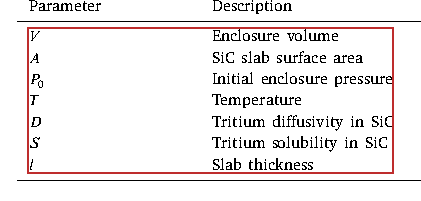

In [41]:
# Choose a representative crop from the actual plan; no paper-specific inventory is used.
sample_region = next(
    (r for r in plan["regions"] if mathematical(r["text"]) and len(r["text"]) > 150),
    next(iter(plan["regions"]), None),
)
if sample_region is not None:
    print("Region:", sample_region["id"], "| physical page:", sample_region["page"])
    print("Uninterpreted text fragments:\n", sample_region["text"][:1200])
    display(Image(filename=sample_region["image_path"], width=950))
else:
    print("No unresolved regions require visual recovery.")


### 6. Validate the vision response format

The vision model proposes a role and, for equations, LaTeX. The validator rejects unsupported roles, missing transcriptions, empty fractions and unbalanced braces. These are limited checks; a syntactically valid formula can still be mathematically wrong.

The following is executable implementation code, copied from the companion script at notebook creation, formatted and annotated by logical block. Comments and spacing are checked to preserve the executable syntax.

In [42]:
# Check the model response format and limited LaTeX invariants before considering a merge.
def validate_response(raw):

    # Remove an optional Markdown fence and require a supported structural role.
    clean = re.sub(r"^```(?:json)?\s*|\s*```$", "", raw.strip())
    result = json.loads(clean)
    if not isinstance(result, dict) or result.get("type") not in ALLOWED:
        raise ValueError("Unsupported structural role")
    if not isinstance(result.get("text"), str):
        raise ValueError("Missing literal text")
    if not isinstance(result.get("uncertainties", []), list):
        raise ValueError("Invalid uncertainties")

    # For equations, reject absent LaTeX, empty fractions and unbalanced braces.
    if result["type"] in ("equation", "equation_group"):
        latex = result.get("latex")
        if not isinstance(latex, str) or not latex.strip():
            raise ValueError("Missing LaTeX")
        if re.search(r"\\frac\s*\{\s*\}|\\frac\s*\{[^{}]*\}\s*\{\s*\}", latex):
            raise ValueError("Empty fraction indicates incomplete transcription")
        if latex.count("{") != latex.count("}"):
            raise ValueError("Unbalanced LaTeX braces")
    return result


### 6.1 Execute only the planned requests

Requests are bound to the exact model revision, crop image, prompt and baseline. Identical requests reuse their actual saved responses. The GPU model is loaded lazily only when a missing request needs inference. No remote model API is called.

The following is executable implementation code, copied from the companion script at notebook creation, formatted and annotated by logical block. Comments and spacing are checked to preserve the executable syntax.

In [43]:
# Reuse matching evidence or run the local vision model only for missing region requests.
def recover(out, limit=None, pages=None):

    # Keep the model unloaded until an actual cache miss requires GPU inference.
    model = None
    processor = None
    out = Path(out)
    manifest = read(out / "region_plan.private.json")
    baseline = read(out / "text_pass/structure.json")
    if (
        hashlib.sha256(Path(manifest["source_pdf"]).read_bytes()).hexdigest()
        != manifest["source_sha256"]
    ):
        raise ValueError("Source PDF changed; re-prepare regions")
    if manifest["baseline_sha256"] != digest(baseline):
        raise ValueError("Text-pass output changed; re-prepare regions")

    # Apply optional diagnostic filters without changing the saved region plan.
    selected = [r for r in manifest["regions"] if not pages or r["page"] in pages]
    if limit is not None:
        selected = selected[:limit]
    (out / "responses").mkdir(exist_ok=True)

    # Index previous responses by their model, prompt and crop identity.
    cache = {}
    for cached_path in list((out / "responses").glob("*.json")) + list(
        (out / "response_history").glob("*.json")
    ):
        item = read(cached_path)
        signature = digest(
            {k: item.get(k) for k in ("model", "revision", "image_sha256", "prompt")}
        )
        cache[signature] = item

    # Verify each request and reuse an exact matching saved response when possible.
    for r in selected:
        path = out / "responses" / f'{r["id"]}.json'
        prompt = PROMPT + r["text"][:6000]
        key = digest(
            {
                "model": MODEL,
                "revision": REVISION,
                "image": r["image_sha256"],
                "prompt": prompt,
                "baseline": manifest["baseline_sha256"],
            }
        )
        if path.exists() and read(path).get("request_sha256") == key:
            continue
        if (
            hashlib.sha256(Path(r["image_path"]).read_bytes()).hexdigest()
            != r["image_sha256"]
        ):
            raise ValueError("Crop image changed")
        signature = digest(
            {
                "model": MODEL,
                "revision": REVISION,
                "image_sha256": r["image_sha256"],
                "prompt": prompt,
            }
        )

        # Reuse equivalent prior evidence while updating its association with the current baseline.
        if signature in cache:
            reused = copy.deepcopy(cache[signature])
            reused.update(
                region_id=r["id"],
                page=r["page"],
                request_sha256=key,
                baseline_sha256=manifest["baseline_sha256"],
                target_node_ids=r["node_ids"],
                target_block_ids=r["block_ids"],
                cache_reused=True,
            )
            if path.exists():
                history = out / "response_history"
                history.mkdir(exist_ok=True)
                previous = read(path)
                save(
                    history
                    / (
                        r["id"]
                        + "."
                        + previous.get("request_sha256", "unknown")[:12]
                        + ".json"
                    ),
                    previous,
                )
            save(path, reused)
            print(
                json.dumps(
                    {"stage": "vision_cache", "region": r["id"], "page": r["page"]}
                ),
                flush=True,
            )
            continue

        # Load the pinned local Hugging Face checkpoint; this path does not call a remote API.
        if model is None:
            import torch
            from PIL import Image
            from transformers import AutoProcessor, Qwen3VLForConditionalGeneration

            weights = (
                ROOT
                / ".local/huggingface/models--Qwen--Qwen3-VL-4B-Instruct/snapshots"
                / REVISION
            )
            model = (
                Qwen3VLForConditionalGeneration.from_pretrained(
                    weights,
                    dtype=torch.bfloat16,
                    attn_implementation="sdpa",
                    local_files_only=True,
                    use_safetensors=True,
                )
                .to("cuda")
                .eval()
            )
            processor = AutoProcessor.from_pretrained(
                weights,
                local_files_only=True,
                min_pixels=256 * 28 * 28,
                max_pixels=1280 * 1280,
            )

        # Pair the target crop with the instruction and literal PDF text fragments.
        image = Image.open(r["image_path"]).convert("RGB")
        started = time.monotonic()
        messages = [
            {
                "role": "user",
                "content": [
                    {"type": "image", "image": image},
                    {"type": "text", "text": prompt},
                ],
            }
        ]
        text = processor.apply_chat_template(
            messages, tokenize=False, add_generation_prompt=True
        )
        inputs = processor(
            text=[text], images=[image], padding=True, return_tensors="pt"
        ).to("cuda")

        # Generate deterministically with a bounded output length.
        with torch.inference_mode():
            tokens = model.generate(
                **inputs, max_new_tokens=1000, do_sample=False, use_cache=True
            )
        raw = processor.batch_decode(
            tokens[:, inputs["input_ids"].shape[1] :],
            skip_special_tokens=True,
            clean_up_tokenization_spaces=False,
        )[0]
        if path.exists():
            history = out / "response_history"
            history.mkdir(exist_ok=True)
            previous = read(path)
            save(
                history
                / (
                    r["id"]
                    + "."
                    + previous.get("request_sha256", "unknown")[:12]
                    + ".json"
                ),
                previous,
            )

        # Keep the raw reply and provenance even when parsing or validation fails.
        record = {
            "region_id": r["id"],
            "page": r["page"],
            "model": MODEL,
            "revision": REVISION,
            "request_sha256": key,
            "baseline_sha256": manifest["baseline_sha256"],
            "image_sha256": r["image_sha256"],
            "target_node_ids": r["node_ids"],
            "target_block_ids": r["block_ids"],
            "prompt": prompt,
            "raw_response": raw,
            "elapsed_seconds": round(time.monotonic() - started, 2),
            "verified": False,
            "review_required": True,
        }
        try:
            if tokens.shape[1] - inputs["input_ids"].shape[1] >= 1000:
                raise ValueError("Generation truncated")
            record["proposal"] = validate_response(raw)
            record["response_valid"] = True
        except Exception as exc:
            record.update(response_valid=False, error=str(exc))
        save(path, record)
        print(
            json.dumps(
                {
                    "stage": "vision",
                    "region": r["id"],
                    "page": r["page"],
                    "type": record.get("proposal", {}).get("type"),
                    "valid": record["response_valid"],
                    "seconds": record["elapsed_seconds"],
                }
            ),
            flush=True,
        )
        del inputs, tokens


In [44]:
print("Local model:", MODEL, "| revision:", REVISION)

# Run missing visual requests or reuse their saved model evidence.
recover(OUTPUT)

# Collect all region responses, including invalid replies, for transparent inspection.
responses = {
    r["id"]: read(OUTPUT / "responses" / (r["id"] + ".json")) for r in plan["regions"]
}
print("Regions with saved model evidence:", len(responses))
show_table(
    [
        {"result": label, "regions": count}
        for label, count in Counter(
            response.get("proposal", {}).get("type", "invalid response")
            for response in responses.values()
        ).most_common()
    ],
    ["result", "regions"],
)


Local model: Qwen/Qwen3-VL-4B-Instruct | revision: ebb281ec70b05090aa6165b016eac8ec08e71b17


Regions with saved model evidence: 182


result,regions
equation,48
paragraph,31
reference,21
unidentified,21
invalid response,21
equation_group,11
table,10
publication_metadata,6
figure,6
caption,4


### 6.2 Complete visual-proposal JSON

This intermediate JSON contains every planned region, its original source-node IDs, and the actual model response or failure. These are proposals before merge acceptance; they are not yet a validated publication structure. Crop geometry remains private.

In [45]:
# Assemble the full intermediate proposal artifact before merge decisions are applied.
visual_proposals = {
    "source": {"pdf": PDF.name, "sha256": SOURCE_SHA256},
    "stage": "visual_proposals_before_merge",
    "model": MODEL,
    "model_revision": REVISION,
    "regions": [
        {
            "region_id": r["id"],
            "page_start": r["page"],
            "page_end": r["page"],
            "source_node_ids": r["node_ids"],
            "selection_reasons": r["reasons"],
            "original_text": r["text"],
            "response_valid": responses[r["id"]].get("response_valid", False),
            "proposal": responses[r["id"]].get("proposal"),
            "raw_response": responses[r["id"]].get("raw_response"),
            "error": responses[r["id"]].get("error"),
            "review_required": True,
        }
        for r in plan["regions"]
    ],
}
visual_json_path = publish_json(
    "03_visual_proposals.json",
    visual_proposals,
    "Stage 3 — Complete visual proposals before merging",
)


<IPython.core.display.JSON object>

Saved: C:\Users\Amarnath Gupta\OneDrive - UC San Diego\Documents\Codex\Teaching\DSE203\publication_structure\outputs\publication_structures\text_then_vision\Simon_2025_TMAP8_manuscript\json_stages\03_visual_proposals.json


## 7. Merge proposals under the schema

The merge stage preserves original source text and source IDs. It rejects stale evidence, unsupported bibliography interpretations, missing equalities and some cases where multiple equations were reduced to one. Known source-check failures are withheld. Uncertain or invalid responses keep the original content unidentified.

Accepted nodes remain **model proposals requiring review**. Their logical section association may also remain unresolved. Source text, model transcription and LaTeX are separate fields. Normalization only repairs doubled escapes before known LaTeX commands and retains the raw response.

A final ledger requires every original observed text block to retain exactly one primary owner. Correcting a false heading promotes its existing children instead of discarding them.

In [46]:
# Apply eligible proposals while preserving source ownership and retaining rejected content.
def merge(out):

    # Load the baseline and reject changes to the PDF or its saved structural interpretation.
    out = Path(out)
    plan = read(out / "region_plan.private.json")
    tree = read(out / "text_pass/structure.json")
    baseline = copy.deepcopy(tree)
    if (
        "source_pdf" in plan
        and hashlib.sha256(Path(plan["source_pdf"]).read_bytes()).hexdigest()
        != plan["source_sha256"]
    ):
        raise ValueError("Source PDF changed")
    if plan["baseline_sha256"] != digest(tree):
        raise ValueError("Baseline changed")

    # Load optional source checks; they apply only to the exact image and response hashes.
    source_reviews = (
        read(out / "source_checks.json").get("checks", [])
        if (out / "source_checks.json").exists()
        else []
    )
    schema = read(
        ROOT.parent
        / "Teaching/DSE203/publication_structure/notebooks/scientific_publication.schema.json"
    )
    observations = read(out / "text_pass/observations.json")
    by_id = {l["id"]: l for l in observations}
    # Conflicting first-pass roles are unresolved until a valid recovery proposal is available.
    for region in plan["regions"]:
        if any("conflicts_with" in reason for reason in region["reasons"]):
            current = index(tree)
            for nid in region["node_ids"]:
                n = current[nid]
                if n["type"] != "custom":
                    n["attributes"].update(
                        original_role=n["type"],
                        custom_type="unidentified",
                        classification_conflict=True,
                    )
                    n["type"] = "custom"
                    n["review_required"] = True

    # Initialize the audit; successful schema checks will not imply semantic correctness.
    report = {
        "model": MODEL,
        "revision": REVISION,
        "planned_regions": len(plan["regions"]),
        "model_calls": 0,
        "merged_regions": [],
        "rejected_regions": [],
        "pending_regions": [],
        "independently_verified_correct": False,
        "equation_recall_verified": False,
        "omitted_targets": plan["omitted_targets"],
    }

    # Evaluate every planned region, preserving pending or rejected content.
    for r in plan["regions"]:
        path = out / "responses" / f'{r["id"]}.json'
        if not path.exists():
            report["pending_regions"].append(r["id"])
            continue
        response = read(path)
        report["model_calls"] += 1

        def reject(reason):
            report["rejected_regions"].append({"region_id": r["id"], "reason": reason})

        # Reject stale evidence before considering the model-assigned role.
        expected_key = digest(
            {
                "model": MODEL,
                "revision": REVISION,
                "image": r["image_sha256"],
                "prompt": PROMPT + r["text"][:6000],
                "baseline": plan["baseline_sha256"],
            }
        )
        if (
            response.get("request_sha256") != expected_key
            or response.get("baseline_sha256") != plan["baseline_sha256"]
            or response.get("image_sha256") != r["image_sha256"]
        ):
            reject("Provenance mismatch")
            continue
        if not response.get("response_valid"):
            reject(response.get("error", "Invalid model response"))
            continue
        matched_review = next(
            (
                check
                for check in source_reviews
                if check.get("image_sha256") == response["image_sha256"]
                and check.get("raw_response_sha256")
                == hashlib.sha256(response["raw_response"].encode()).hexdigest()
            ),
            None,
        )
        if matched_review and matched_review["outcome"] == "fail":
            reject("Source check failed: " + matched_review["finding"])
            continue
        proposal = validate_response(response["raw_response"])
        role = proposal["type"]

        # Apply conservative mathematical checks, including omitted equalities and merged equation labels.
        if role in ("equation", "equation_group"):
            if re.fullmatch(r"\s*\d+\s*", r["text"]):
                reject("Isolated numeral is not evidence of an equation")
                continue
            if "=" in r["text"] and "=" not in proposal["latex"]:
                reject("Equation equality omitted")
                continue
            labels = set(re.findall(r"\((\d{1,3})\)\s*(?:\n|$)", r["text"]))
            if len(labels) > 1 and role != "equation_group":
                reject("Multiple source equations reduced to a single equation")
                continue
        if (
            role == "reference"
            and len(re.findall(r"(?:^|\n)\s*\[?\d{1,4}[\].)]\s+", r["text"])) > 1
        ):
            reject("Multiple bibliography entries require segmentation")
            continue
        if role == "reference" and not (
            re.search(r"\b(?:18|19|20)\d{2}\b|10\.\d{4,9}/", r["text"])
            and len(r["text"].split()) >= 6
        ):
            reject("Inline reference or insufficient bibliographic evidence")
            continue
        if role == "unidentified":
            reject("Model could not assign a single role")
            continue

        # Protect already interpreted nodes outside the permitted recovery targets.
        current = index(tree)
        targets = [current[n] for n in r["node_ids"]]
        if any(
            n.get("attributes", {}).get("custom_type") != "unidentified"
            and "mathematical_content_conflicts_with_heading_role" not in r["reasons"]
            for n in targets
        ):
            reject("Protected interpretation")
            continue
        # The model supplies supplemental interpretation; original text and primary source ownership stay literal.
        text = "\n".join(by_id[i]["text"] for i in r["block_ids"])
        if role == "heading":
            role = "section"

        # Construct a review-required replacement with original text and separate model interpretation.
        new = {
            "id": "recovered_" + r["id"],
            "type": role,
            "page_start": r["page"],
            "page_end": r["page"],
            "children": [],
            "text": text,
            "review_required": True,
            "attributes": {
                "observation_ids": r["block_ids"],
                "recovered_from": r["node_ids"],
                "model_transcription": proposal["text"],
                "uncertainties": proposal.get("uncertainties", []),
                "recovery_status": "model_proposal_requires_review",
                "decision": {
                    "rule": "Text-pass unresolved region classified from its crop",
                    "model": MODEL,
                    "model_revision": REVISION,
                    "image_sha256": r["image_sha256"],
                    "evidence_file": str(path.resolve()),
                    "source": [
                        {
                            "block_id": i,
                            "page": by_id[i]["page"],
                            "quote": by_id[i]["text"],
                        }
                        for i in r["block_ids"]
                    ],
                    "verified": False,
                    "review_required": True,
                },
            },
        }
        if role in ("equation", "equation_group"):
            latex = proposal["latex"]
            # Correct transport over-escaping only for known LaTeX commands, retaining the original.
            commands = r"frac|sqrt|sum|int|left|right|sin|cos|tan|exp|log|ln|infty|alpha|beta|gamma|lambda|rho|nabla|partial|theta|pi|Delta|Omega|begin|end|text|tag|cdot|times|quad|qquad|mathrm|mathbf|operatorname|sec|tanh"
            normalized = re.sub(
                r"\\\\(?=(?:" + commands + r")\b|[{}])", lambda m: "\\", latex
            )
            new["attributes"]["latex"] = normalized
            if normalized != latex:
                new["attributes"][
                    "latex_normalization"
                ] = "Collapsed doubled escapes before known LaTeX commands; raw response retained"
        if proposal.get("label") is not None:
            new["label"] = str(proposal["label"])
        if role == "section":
            new["title"] = proposal["text"]
            new["attributes"]["hierarchy_status"] = "unresolved_level_and_parent"

        # Choose a broad schema container; recovered heading levels and parents may remain unresolved.
        destination = (
            "back_matter"
            if role == "reference"
            else "front_matter" if role == "abstract" else "body"
        )
        holder = next(
            n for n in tree["document"]["children"] if n["type"] == destination
        )
        if role == "reference":
            refs = next(
                (n for n in holder["children"] if n["type"] == "references"), None
            )
            if refs is None:
                refs = {
                    "id": "recovered_references",
                    "type": "references",
                    "page_start": r["page"],
                    "page_end": r["page"],
                    "children": [],
                }
                holder["children"].append(refs)
            holder = refs
        # Remove targets postorder so nested target headings cannot be promoted twice.
        target_ids = set(r["node_ids"])

        def remove_targets(parent):
            children = []
            for child in parent["children"]:
                remove_targets(child)
                children.extend(
                    child["children"] if child["id"] in target_ids else [child]
                )
            parent["children"] = children

        remove_targets(tree["document"])
        holder["children"].append(new)
        report["merged_regions"].append(
            {
                "region_id": r["id"],
                "type": role,
                "page": r["page"],
                "source_nodes": len(targets),
            }
        )

    # Parse citation fields only for references that survived the merge checks.
    recovered_refs = [
        n
        for n in walk(tree["document"])
        if n["type"] == "reference" and n.get("attributes", {}).get("recovered_from")
    ]
    if recovered_refs:
        from document_structure_extractor import ExtractionContext
        from citation_extractor import enrich_citations

        ctx = ExtractionContext(schema, out)
        ctx.sequence = max(
            [
                int(n["id"][1:])
                for n in walk(tree["document"])
                if re.fullmatch(r"x\d+", n["id"])
            ]
            + [0]
        )
        report["recovered_citations"] = enrich_citations(
            {"document": {"children": recovered_refs, "type": "article"}}, ctx
        )

    # Update evidence relations to replacement IDs and keep their verification status false.
    remap = {
        old: n["id"]
        for n in walk(tree["document"])
        for old in n.get("attributes", {}).get("recovered_from", [])
    }
    for relation in tree["extraction"].get("relations", []):
        for endpoint in ("from", "to", "section_id"):
            if relation.get(endpoint) in remap:
                relation[endpoint] = remap[relation[endpoint]]
                relation["review_required"] = True
                relation["verified"] = False
    expand_ranges(tree["document"])

    # Every original source block must retain exactly one primary owner.
    def ledger(t):
        return Counter(
            i
            for n in walk(t["document"])
            for i in n.get("attributes", {}).get("observation_ids", [])
        )

    # Require exact, unique source ownership before validating and writing the final JSON.
    before, after = ledger(baseline), ledger(tree)
    assert before == after and all(
        v == 1 for v in after.values()
    ), "Source ownership changed during visual recovery"
    report["validation"] = validate_structure(tree, schema)
    report["coverage_preserved"] = True
    report["unidentified_nodes_before"] = sum(
        n.get("attributes", {}).get("custom_type") == "unidentified"
        for n in walk(baseline["document"])
    )
    report["unidentified_nodes_after"] = sum(
        n.get("attributes", {}).get("custom_type") == "unidentified"
        for n in walk(tree["document"])
    )
    report["source_checks"] = source_reviews
    report["merged_type_counts"] = dict(
        Counter(x["type"] for x in report["merged_regions"])
    )
    tree["extraction"]["visual_recovery"] = {
        "provider": "local_huggingface",
        "model": MODEL,
        "revision": REVISION,
        "order": "text_pass_then_unidentified_regions",
        "planned_regions": report["planned_regions"],
        "model_calls": report["model_calls"],
        "merged_regions": len(report["merged_regions"]),
        "pending_regions": len(report["pending_regions"]),
        "all_proposals_require_review": True,
    }

    # Persist the complete merged structure and the audit of accepted and rejected regions.
    save(out / "structure.json", tree)
    save(out / "recovery_audit.json", report)
    print(
        json.dumps(
            {
                k: v
                for k, v in report.items()
                if k
                not in (
                    "merged_regions",
                    "rejected_regions",
                    "pending_regions",
                    "omitted_targets",
                )
            },
            indent=2,
        ),
        flush=True,
    )
    return tree, report


In [47]:
# Capture verbose implementation diagnostics; display the decisive results below.
from contextlib import redirect_stdout

# Capture verbose diagnostics while constructing and validating the merged publication tree.
merge_log = io.StringIO()
with redirect_stdout(merge_log):
    final_tree, recovery_audit = merge(OUTPUT)
assert recovery_audit["coverage_preserved"]
assert not recovery_audit["pending_regions"], "Some planned requests are still pending"
print("Schema and page checks:", recovery_audit["validation"])
print("Merged proposal regions:", len(recovery_audit["merged_regions"]))
print(
    "Rejected or still-unidentified regions:", len(recovery_audit["rejected_regions"])
)
print("Source-block ownership preserved:", recovery_audit["coverage_preserved"])


Schema and page checks: {'schema_valid': True, 'page_ranges_valid': True, 'unique_ids': True, 'nodes': 1424}
Merged proposal regions: 116
Rejected or still-unidentified regions: 66
Source-block ownership preserved: True


## 8. What the structural model adds

The table compares representational capabilities for the same source. Node counts are **not accuracy measurements**. The flat baseline retains text but does not encode roles. The informed representations make role-based queries, nesting, page containment, unresolved-content inspection and provenance checks explicit.

In [48]:
# Compare representational capabilities; node counts are not measurements of accuracy.
text_counts = Counter(n["type"] for n in walk(text_tree["document"]))
final_counts = Counter(n["type"] for n in walk(final_tree["document"]))
rows = [
    {
        "property": "physical PDF pages",
        "page-text baseline": flat_document["source"]["pages"],
        "schema + local rules": text_tree["source"]["pages"],
        "schema + targeted vision": final_tree["source"]["pages"],
    }
]
for role in [
    "section",
    "subsection",
    "subsubsection",
    "figure",
    "table",
    "equation",
    "equation_group",
    "references",
    "reference",
    "citation",
]:
    rows.append(
        {
            "property": role + " nodes",
            "page-text baseline": 0,
            "schema + local rules": text_counts[role],
            "schema + targeted vision": final_counts[role],
        }
    )
rows += [
    {
        "property": "explicit unidentified nodes",
        "page-text baseline": "not represented",
        "schema + local rules": recovery_audit["unidentified_nodes_before"],
        "schema + targeted vision": recovery_audit["unidentified_nodes_after"],
    },
    {
        "property": "per-element page intervals",
        "page-text baseline": "page only",
        "schema + local rules": "yes",
        "schema + targeted vision": "yes",
    },
    {
        "property": "source-evidence and review status",
        "page-text baseline": "not represented",
        "schema + local rules": "yes",
        "schema + targeted vision": "yes",
    },
]
show_table(
    rows,
    [
        "property",
        "page-text baseline",
        "schema + local rules",
        "schema + targeted vision",
    ],
)
print(
    "Mechanical reduction in unidentified-node count:",
    recovery_audit["unidentified_nodes_before"]
    - recovery_audit["unidentified_nodes_after"],
)
print("This reduction measures reclassification, not verified recovery accuracy.")


property,page-text baseline,schema + local rules,schema + targeted vision
physical PDF pages,26,26,26
section nodes,0,4,7
subsection nodes,0,10,10
subsubsection nodes,0,30,18
figure nodes,0,22,28
table nodes,0,9,19
equation nodes,0,0,45
equation_group nodes,0,0,11
references nodes,0,0,0
reference nodes,0,0,0


Mechanical reduction in unidentified-node count: 300
This reduction measures reclassification, not verified recovery accuracy.


### 8.1 A query that uses the model

“Show equation interpretations, their physical pages, LaTeX, and review status” is a direct structural query. With the page-text baseline, those roles must first be inferred again. A group may contain multiple equations; its count should not be reported as a count of individual equations.

In [49]:
# Query equation roles directly from the hierarchy and show their page and review information.
equations = [
    n
    for n in walk(final_tree["document"])
    if n["type"] in ("equation", "equation_group")
]
show_table(
    [
        {
            "id": n["id"],
            "type": n["type"],
            "pages": f"{n['page_start']}–{n['page_end']}",
            "label": n.get("label", ""),
            "LaTeX preview": n.get("attributes", {}).get("latex", "")[:130],
            "review required": n.get("review_required", True),
        }
        for n in equations[:12]
    ],
    ["id", "type", "pages", "label", "LaTeX preview", "review required"],
)


id,type,pages,label,LaTeX preview,review required
recovered_r0023,equation,7–7,1,F R(t) = 1.0 - \sum_{n=1}^{\infty} \frac{2 L \sec(\alpha_n) \exp\left(-\alpha_n^2 [D t / l^2]\right)}{L(L+1) + \alpha_n^2},True
recovered_r0025,equation,8–8,2,L = \frac{lA}{V\phi},True
recovered_r0031,equation,8–8,,L'\sum_{n=1}^{\infty}\frac{\exp\left(-a_n^2L'\right)\sin(a_nx)}{\left[l(a_n^2+L'^2)+L'\right]\sin(a_nl)},True
recovered_r0032,equation,8–8,,STAk,True
recovered_r0033,equation,8–8,9,\alpha_{n} = \frac{L}{\tan(\alpha_{n} l)},True
recovered_r0034,equation,8–8,,FR(t) = 1.0 - \frac{P(t)}{P_0} = 1 - 2L' \sum_{n=1}^{\infty} \frac{\exp\left(-\alpha_n^2 D t\right)}{l(\alpha_n^2 + L'^2) + L'},True
recovered_r0035,equation,8–8,6,"FR(t) = 1.0 - \frac{P(t)}{P_0},",True
recovered_r0036,equation_group,8–8,unidentified,"\alpha_n = \frac{L}{\tan \alpha_n}.\quad(4)\quad C(x,t) = 2S P_0 L' \sum_{n=1}^{\infty} \frac{\exp\left(-\alpha_n^2 D t\right) \si",True
recovered_r0037,equation,8–8,,l' = \frac{ST A k_b}{V},True
recovered_r0038,equation_group,8–8,"5, 10","RM SPE = \sqrt{\sum (x_{TMAP} - x_{ref})^2 / n} / \sum x_{ref} / n,\quad P(t) = \frac{C(l,t)}{S} = 2P_0 L' \sum_{n=1}^{\infty} \fr",True


### 8.2 Inspect the resulting JSON

The next cell displays and exports the **complete final JSON**, including every structural node, its page interval, source text, hierarchy, evidence and unresolved content. This is the result constructed by the merge step, not a summary or one-node example. The following cell then zooms in on a single equation for readability. Geometry remains private.

In [50]:
validate_structure(final_tree, SCHEMA)
final_json_path = publish_json(
    "04_final_structure.json", final_tree, "Stage 4 — Complete final publication JSON"
)
assert read(final_json_path) == read(OUTPUT / "structure.json")


<IPython.core.display.JSON object>

Saved: C:\Users\Amarnath Gupta\OneDrive - UC San Diego\Documents\Codex\Teaching\DSE203\publication_structure\outputs\publication_structures\text_then_vision\Simon_2025_TMAP8_manuscript\json_stages\04_final_structure.json


In [51]:
# Zoom in on one equation after displaying the complete final publication JSON.
example = next(
    (n for n in equations if str(n.get("label", "")).strip("() ") == "46"),
    equations[0] if equations else final_tree["document"],
)
display(JSON(example, expanded=False))
if example.get("attributes", {}).get("latex"):
    display(Math(example["attributes"]["latex"]))
print("Complete structure:", OUTPUT / "structure.json")


<IPython.core.display.JSON object>

<IPython.core.display.Math object>

Complete structure: C:\Users\Amarnath Gupta\OneDrive - UC San Diego\Documents\Codex\Teaching\DSE203\publication_structure\outputs\publication_structures\text_then_vision\Simon_2025_TMAP8_manuscript\structure.json


## 9. Current mistakes and source checks

Schema validation and complete block ownership do not certify mathematical or structural correctness. The saved source checks compare sampled transcriptions with rendered source pages. Some transcriptions were rejected for altered grouping or subscripts. The model can also misclassify fragments, miss content, or leave a section relationship unresolved.

The Simon PDF has three report front pages followed by the journal article. This complicates title/front-matter interpretation. Its mixed columns and mathematical typesetting still cause errors. The current example is a demonstration of an explicit document model and an auditable recovery process, not a claim that this paper has been extracted correctly in full.

In [52]:
# Show the scope of optional source checks and whether their evidence still matches this run.
checks = (
    read(OUTPUT / "source_checks.json")
    if (OUTPUT / "source_checks.json").exists()
    else {"checks": []}
)

# Match source checks to exact crop and response hashes, rather than equation labels alone.
current_evidence = {
    (r["image_sha256"], hashlib.sha256(r["raw_response"].encode()).hexdigest())
    for r in responses.values()
}
show_table(
    [
        {
            "source page": c["source_page"],
            "equation": c["equation_label"],
            "outcome": c["outcome"],
            "matches current evidence": (c["image_sha256"], c["raw_response_sha256"])
            in current_evidence,
            "evidence": c["finding"],
        }
        for c in checks["checks"]
    ],
    ["source page", "equation", "outcome", "matches current evidence", "evidence"],
)
if not checks["checks"]:
    print(
        "No independent transcription source checks are recorded for this input; model proposals remain unverified."
    )
show_table(recovery_audit["rejected_regions"][:15], ["region_id", "reason"])

# Expose unresolved nodes so incomplete interpretation is visible rather than hidden.
remaining = [
    n
    for n in walk(final_tree["document"])
    if n.get("attributes", {}).get("custom_type") == "unidentified"
]
print("Remaining unidentified nodes:", len(remaining))
display(
    JSON(
        [
            {
                k: n[k]
                for k in ("id", "type", "page_start", "page_end", "text")
                if k in n
            }
            for n in remaining[:3]
        ]
    )
)


source page,equation,outcome,matches current evidence,evidence
7,1,sampled_pass,True,"Compared with physical PDF page 7: FR(t), leading 1.0, summation limits, secant, exponential and denominator agree."
14,42,fail,False,"In source equation (42), the exponential multiplies the summation term inside the outer braces. The proposal closes the braces before the exponential and multiplies the entire expression by it."
14,43,fail,False,"Source equation (43) has material names PyC and SiC wholly in the subscripts. The proposal uses D_{P}yC and D_{Si}C, which changes the mathematical expression."
14,46,sampled_pass,True,"Compared with physical PDF page 14: rho C_P dT/dt, the two gradient operators, k, T, Q and label (46) agree."
14,44,sampled_pass,True,"Compared the complete boxed fraction with physical PDF page 14: both numerator terms, denominator factors and equation label agree in this visual sample."


region_id,reason
r0004,Inline reference or insufficient bibliographic evidence
r0012,Inline reference or insufficient bibliographic evidence
r0018,Model could not assign a single role
r0021,Inline reference or insufficient bibliographic evidence
r0022,Inline reference or insufficient bibliographic evidence
r0030,Isolated numeral is not evidence of an equation
r0044,Model could not assign a single role
r0050,Invalid \escape: line 4 column 56 (char 93)
r0051,Model could not assign a single role
r0053,Invalid \escape: line 4 column 58 (char 101)


Remaining unidentified nodes: 891


<IPython.core.display.JSON object>

## 10. Final invariants and saved artifacts

We finish by checking schema conformance, page containment and exact preservation of primary text-block ownership. We also ensure no structural node exports bounding-box fields. The complete JSON, audits, model responses and crops remain available for inspection and further work.

In [53]:
# Check the final schema and page invariants before recording artifact locations.
final_validation = validate_structure(final_tree, SCHEMA)


# Count primary source-block owners so missing or duplicate assignments can be detected.
def ownership(document):
    return Counter(
        block
        for n in walk(document["document"])
        for block in n.get("attributes", {}).get("observation_ids", [])
    )


# Require identical source ownership before and after visual recovery.
assert ownership(text_tree) == ownership(final_tree)
assert all(count == 1 for count in ownership(final_tree).values())
assert all("bbox" not in n and "source" not in n for n in walk(final_tree["document"]))
assert all("page_start" in n and "page_end" in n for n in walk(final_tree["document"]))
print("All mechanical invariants passed.")

# Record reproducible artifact paths, input/model identity and the semantic-verification limit.
artifact_summary = {
    "source": PDF.name,
    "source_sha256": SOURCE_SHA256,
    "schema": SCHEMA["$id"],
    "model": MODEL,
    "model_revision": REVISION,
    "text_pass": str(OUTPUT / "text_pass" / "structure.json"),
    "final_structure": str(OUTPUT / "structure.json"),
    "json_stages": {
        "flat_text": str(flat_json_path),
        "text_structure": str(text_json_path),
        "visual_proposals": str(visual_json_path),
        "final_structure": str(final_json_path),
    },
    "recovery_audit": str(OUTPUT / "recovery_audit.json"),
    "source_checks": str(OUTPUT / "source_checks.json"),
    "semantically_verified_correct": False,
}
save(OUTPUT / "notebook_artifact_summary.json", artifact_summary)
display(JSON(artifact_summary))


All mechanical invariants passed.


<IPython.core.display.JSON object>

## What this example demonstrates

A possible model of scientific-publication structure makes the representation more meaningful: content has roles, containment, page intervals, provenance and explicit uncertainty. Those properties support targeted recovery and queries that a flat page-text representation does not directly support.

The current errors remain visible rather than being hidden by schema-valid JSON. Establishing improved **accuracy** would require a separately annotated evaluation set and measurements of heading hierarchy, element boundaries, equation transcription and citation parsing. This notebook demonstrates the representational benefit and a working method for investigating those questions.